<a href="https://colab.research.google.com/github/neouuuu/TPE-Fundamentos-de-la-Ciencia-de-Datos/blob/main/TPE_Ciencia_de_Datos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Este es el archivo que va a terminar siendo el Jupyter Notebook para la entrega. (También ponemos toda la info y teoría que tendría que ir en el informe así que va a estar todo medio sobre explicado pero primero que quede todo acá y después armamos cada cosa).


Este es el Jupyter Notebook correspondiente al Trabajo Práctico Especial, Cursada 2026


Introducción al grupo y al trabajo:

Somos el grupo 33, integrado por:

Neo Allende

Francisco Maiaru

Manuel Lara Lambrecht

A nuestro grupo le ha tocado trabajar con el enunciado y dataset de CKD-NHANES.

En este trabajo se analizarán los datos provistos, se formularán hipótesis y se tratará de buscar relaciones entre las variables del estudio.

Constará de 4 secciones:

1. Una descripción de la fuente de los datos y un análisis exploratorio inicial de la base.
2. Limpieza de la base.
3. Planteo de 3 hipótesis de interés, univariada, bivariada y multivariada
4. La validación de las hipótesis planteadas, y de 3 hipótesis más provistas por la cátedra



# Primera Sección: Análisis preliminar de los datos y la fuente


## 1. Acerca de NHANES
La **NHANES** (*National Health and Nutrition Examination Survey* / Encuesta Nacional de Examen de Salud y Nutrición) es un programa de estudios diseñado para evaluar el estado de salud y nutrición de adultos y niños en los Estados Unidos.

Es llevado a cabo por el **NCHS** (*National Center for Health Statistics* / Centro Nacional de Estadísticas de Salud), que forma parte de los **CDC** (*Centers for Disease Control and Prevention* / Centros para el Control y la Prevención de Enfermedades).

---

## 2. Metodología de Recolección de Datos
NHANES combina **entrevistas directas** con **exámenes físicos** y **pruebas de laboratorio**.

1. **Fase de Entrevistas:** Entrevistadores visitan los hogares para recolectar datos demográficos, socioeconómicos, de comportamientos (tabaquismo, alcohol, actividad física) y antecedentes médicos.
2. **Fase de Exámenes:** Luego los participantes son trasladados a clínicas móviles donde se realizan:
   * **Mediciones:** Peso, talla, índice de masa corporal (IMC), circunferencia de cintura y presión arterial.
   * **Muestras:** Extracción de sangre y recolección de orina.
   * **Análisis:** Perfil lipídico, glucemia, entre otros marcadores.

### Muestreo representativo
NHANES utiliza un diseño de **muestreo probabilístico por etapas**. Esto significa que seleccionan condados, luego segmentos de vecindarios, hogares y, finalmente, personas dentro de esos hogares. Además, sobre-muestrean intencionalmente a ciertos grupos poblacionales (como adultos mayores o minorías étnicas) para garantizar precisión estadística en esos subgrupos.

---

## 3. Contexto Particular del Ciclo 2021–2023
* Debido a la pandemia de COVID-19, las operaciones de campo del ciclo tradicional de 2019-2020 se suspendieron en marzo de 2020.
* NHANES reanudó la recolección de datos en campo en agosto de 2021, completando el ciclo en agosto de 2023.
* Este conjunto representa el **primer ciclo completo de datos recopilados tras la interrupción pandémica**, reflejando el estado de salud de la población estadounidense no institucionalizada durante la transición y recuperación de la pandemia.

---

## 4. Objetivos de la Encuesta NHANES
La encuesta persigue varios objetivos estratégicos:

* **Monitoreo de prevalencia de enfermedades.**
* **Identificación de factores de riesgo:** Analizar la relación entre marcadores de estilo de vida y el desarrollo de patologías renales y cardiovasculares.
* **Formulación y evaluación de políticas públicas:** Aportar evidencia para diseñar guías de salud pública, estrategias de prevención y evaluar programas sanitarios nacionales.
* **Establecimiento de estándares nacionales:** Definir rangos de referencia para mediciones corporales y valores de laboratorio (por ejemplo, estimaciones de filtrado glomerular o tablas de crecimiento).

---

## 5. Sobre la Temática Particular de este Trabajo
La **Enfermedad Renal Crónica (ERC)** o *Chronic Kidney Disease* (CKD) es una condición de salud que se caracteriza por la alteración persistente en la estructura o en la función de los riñones. Su desarrollo está vinculado a factores de riesgo metabólicos y cardiovasculares, como la **diabetes** y la **hipertensión arterial**, así como la edad, el tabaquismo, el exceso de peso corporal y factores socioeconómicos.

Se analiza un conjunto de datos procedente de la Encuesta Nacional de Examen de Salud y Nutrición (NHANES) realizada en Estados Unidos entre los años **2021 y 2023**. Esta base de datos combina:

* **Variables demográficas y socioeconómicas:** Edad, sexo, nivel de ingresos, entre otras.
* **Mediciones clínicas:** Antropometría (medidas corporales) y presión arterial, análisis de sangre y orina específicos para evaluar el perfil metabólico y la función renal.
* **Antecedentes clínicos y de estilo de vida:** Diagnósticos previos declarados y hábitos (como el consumo de tabaco).
* **Variables derivadas:** Indicadores calculados para la estimación de la función renal.

---

## 6. Fuentes Consultadas
* **Centers for Disease Control and Prevention (CDC) / National Center for Health Statistics (NCHS):**
  * *NHANES - About the National Health and Nutrition Examination Survey:*  
    [https://www.cdc.gov/nchs/nhanes/about_nhanes.htm](https://www.cdc.gov/nchs/nhanes/about_nhanes.htm)
* **NCHS Data Documentation, Codebooks, and SAS Data Sets (2021-2023 Cycle):**
  * *NHANES 2021-2023 Data Release Overview:*  
    [https://wwwn.cdc.gov/nchs/nhanes/continuousnhanes/default.aspx?Cycle=2021-2023](https://wwwn.cdc.gov/nchs/nhanes/continuousnhanes/default.aspx?Cycle=2021-2023)
* **NHANES Analytic Guidelines & Sample Design:**
  * *National Center for Health Statistics. Key Statistics and Survey Methods:*  
    [https://www.cdc.gov/nchs/nhanes/analyticguidelines.htm](https://www.cdc.gov/nchs/nhanes/analyticguidelines.htm)

Acceso y primer contacto con el dataset:

In [ ]:
import pandas as pd
import os

#Como está en el repositorio
dataset = 'dataset.csv'

# Al if lo tenemos que sacar en el Jupyter, como es colab tengo que cargarlo del github

# Si el dataset no está en el directorio local (típico en Google Colab recién abierto)
if not os.path.exists(dataset):
    print("Detectado entorno Colab / dataset no encontrado localmente.")
    # Opción A: Descarga automática directamente desde tu repositorio de GitHub (Recomendada)
    # Reemplaza la URL por la de tu dataset raw en GitHub
    url_raw = "https://raw.githubusercontent.com/neouuuu/TPE-Fundamentos-de-la-Ciencia-de-Datos/refs/heads/main/dataset.csv"
    dataframe = pd.read_csv(url_raw)
    # Guardamos una copia local para mantener consistencia
    dataframe.to_csv(dataset, index=False)
    print("Dataset descargado desde GitHub correctamente.")


# Esto solo tiene que quedar
else:

    # Carga estándar local (sirve tanto para Jupyter Notebook local como para Colab si el dataset ya existe)
    dataframe = pd.read_csv(dataset)
    print("Dataset cargado localmente con éxito.")



Dataset cargado localmente con éxito.


In [ ]:
# Son 29 variables y no te las muestras todas sin esta opción
pd.set_option('display.max_columns', None)

# Imprimimos algunas filas para observar como está formada la tabla
dataframe.head(15)

,participant_id,age,gender,ethnicity,education_level,poverty_income_ratio,bmi,weight_kg,height_cm,bp_systolic,bp_diastolic,serum_creatinine,blood_urea_nitrogen,albumin_serum,phosphorus,bicarbonate,calcium,uric_acid,urine_creatinine,urine_albumin,albumin_creatinine_ratio,diabetes_diagnosed,insulin_use,diabetes_pills,ever_smoked,current_smoker,egfr,ckd_stage,ckd_present
0,130378.0,43.0,Male,Non-Hispanic Asian,5.0,5.00,27.0,86.9,179.5,135.0,98.0,0.80,11.0,4.3,3.7,24.0,9.6,5.1,136.0,23.12,17.00,2.0,NaN,NaN,1.0,3.0,112.61,No CKD,0
1,130379.0,66.0,Male,Non-Hispanic White,5.0,5.00,33.5,101.8,174.2,121.0,84.0,0.79,24.0,3.9,3.2,25.0,9.4,8.5,64.0,4.25,6.64,2.0,NaN,NaN,1.0,3.0,97.98,No CKD,0
2,130380.0,44.0,Female,Other Hispanic,3.0,1.41,29.7,69.4,152.9,111.0,79.0,0.64,10.0,3.7,3.8,25.0,9.4,4.4,157.0,12.43,7.92,1.0,2.0,1.0,2.0,NaN,111.69,No CKD,0
3,130381.0,5.0,Female,Other/Multiracial,NaN,1.53,23.8,34.3,120.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,208.0,16.12,7.75,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1
4,130382.0,2.0,Male,Non-Hispanic White,NaN,3.60,NaN,13.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1
5,130383.0,3.0,Female,Other Hispanic,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1
6,130384.0,43.0,Male,Mexican American,2.0,0.63,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN,2.0,NaN,NaN,Unknown,1
7,130385.0,65.0,Female,Non-Hispanic White,3.0,5.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,2.0,2.0,NaN,NaN,Unknown,1
8,130386.0,34.0,Male,Mexican American,4.0,1.33,30.2,90.6,173.3,110.0,72.0,0.82,17.0,4.3,3.3,21.0,9.5,6.0,113.0,4.60,4.07,2.0,NaN,NaN,1.0,3.0,118.21,No CKD,0
9,130387.0,68.0,Female,Non-Hispanic White,5.0,1.32,42.6,103.5,155.9,143.0,76.0,0.76,15.0,3.7,3.5,24.0,9.3,6.2,23.0,5.93,25.78,2.0,NaN,NaN,2.0,NaN,85.30,Stage 2 (Mildly Decreased),1


Observando variables:

In [ ]:
# Vamos a ver información sobre las variables del dataset, se observa que hay 11933 filas, 29 variables y las cantidad de respuestas no nulas para cada una.
dataframe.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11933 entries, 0 to 11932
Data columns (total 29 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   participant_id            11933 non-null  float64
 1   age                       11933 non-null  float64
 2   gender                    11933 non-null  object 
 3   ethnicity                 11933 non-null  object 
 4   education_level           7794 non-null   float64
 5   poverty_income_ratio      9892 non-null   float64
 6   bmi                       8471 non-null   float64
 7   weight_kg                 8754 non-null   float64
 8   height_cm                 8499 non-null   float64
 9   bp_systolic               7517 non-null   float64
 10  bp_diastolic              7517 non-null   float64
 11  serum_creatinine          6326 non-null   float64
 12  blood_urea_nitrogen       6326 non-null   float64
 13  albumin_serum             6366 non-null   float64
 14  phosph

## Diccionario de Variables y Clasificación Estadística

### Identificación y características demográficas

| Variable | Tipo Estadístico | Qué representa |
| :--- | :--- | :--- |
| **`participant_id`** | Identificador Único | Código único de la persona. Aunque se almacena como número, no tiene magnitud ni orden clínico y no debería usarse como predictor. |
| **`age`** | Numérica Discreta | Edad (medida en años enteros). El valor 80 agrupa a las personas de 80 años o más. El cero puede aparecer como un número positivo extremadamente pequeño por la conversión del archivo. |
| **`gender`** | Categórica Nominal Dicotómica | Sexo registrado con las categorías *Male* y *Female*. |
| **`ethnicity`** | Categórica Nominal | Grupo étnico informado: *Mexican American*, *Other Hispanic*, *Non-Hispanic White*, *Non-Hispanic Black*, *Non-Hispanic Asian* u *Other/Multiracial*. |
| **`education_level`** | Categórica Ordinal | Máximo nivel educativo informado para participantes en edad de responder. Posee un orden jerárquico intrínseco. |
| **`poverty_income_ratio`** | Numérica Continua | Ingreso familiar dividido por el umbral de pobreza correspondiente al hogar. Cero indica ingreso muy bajo y 5 representa el límite superior agrupado. |

---

### Medidas corporales y presión arterial

| Variable | Tipo Estadístico | Unidad | Qué representa |
| :--- | :--- | :--- | :--- |
| **`bmi`** | Numérica Continua | kg/m² | Índice de masa corporal calculado como peso dividido por altura al cuadrado. Resume tamaño corporal, pero no mide directamente composición corporal. |
| **`weight_kg`** | Numérica Continua | kg | Peso corporal medido en kilogramos. |
| **`height_cm`** | Numérica Continua | cm | Altura o longitud corporal medida en centímetros. |
| **`bp_systolic`** | Numérica Continua | mmHg | Presión arterial sistólica, es decir, la presión máxima durante la contracción del corazón. |
| **`bp_diastolic`** | Numérica Continua | mmHg | Presión arterial diastólica, es decir, la presión entre latidos. Debe interpretarse junto con la sistólica. |

---

### Análisis de sangre

| Variable | Tipo Estadístico | Tipo / Unidad | Qué representa |
| :--- | :--- | :--- | :--- |
| **`serum_creatinine`** | Numérica Continua | mg/dL | Concentración de creatinina en sangre. Es un marcador indirecto de filtrado renal y participa en el cálculo de eGFR. |
| **`blood_urea_nitrogen`** | Numérica Continua | mg/dL | Nitrógeno ureico en sangre. Refleja productos nitrogenados y puede variar por función renal, hidratación y metabolismo proteico. |
| **`albumin_serum`** | Numérica Continua | g/dL | Albúmina en sangre. Puede relacionarse con nutrición, inflamación, función hepática y pérdidas de proteínas. |
| **`phosphorus`** | Numérica Continua | mg/dL | Fósforo sérico. Los riñones participan en su regulación y puede alterarse en enfermedad renal avanzada. |
| **`bicarbonate`** | Numérica Continua | mmol/L | Bicarbonato sérico, indicador del equilibrio ácido base. Valores bajos pueden acompañar una menor capacidad renal para manejar ácidos. |
| **`calcium`** | Numérica Continua | mg/dL | Calcio total en sangre. Se interpreta junto con albúmina, fósforo y contexto clínico. |
| **`uric_acid`** | Numérica Continua | mg/dL | Ácido úrico en sangre, producto del metabolismo de purinas que se elimina en parte por los riñones. |

---

### Análisis de orina

| Variable | Tipo Estadístico | Unidad | Qué representa |
| :--- | :--- | :--- | :--- |
| **`urine_creatinine`** | Numérica Continua | mg/dL | Concentración de creatinina en una muestra de orina. Se usa para ajustar la albúmina por el grado de concentración de la muestra. |
| **`urine_albumin`** | Numérica Continua | µg/mL | Concentración de albúmina en orina. Valores elevados pueden indicar pérdida renal de proteínas. |
| **`albumin_creatinine_ratio`** | Numérica Continua | mg/g | Relación albúmina creatinina en orina. Es la medida normalizada de albuminuria y participa en la asignación de algunas categorías renales. |

---

### Antecedentes y tabaquismo

| Variable | Tipo Estadístico | Qué representa |
| :--- | :--- | :--- |
| **`diabetes_diagnosed`** | Categórica Ordinal | Respuesta a si un profesional de salud diagnosticó diabetes. Incluye nivel o categoría intermedia (*borderline*). |
| **`insulin_use`** | Categórica Nominal Dicotómica | Indica si la persona con antecedente de diabetes usa insulina. La pregunta se aplica a un subconjunto. |
| **`diabetes_pills`** | Categórica Nominal Dicotómica | Indica si toma medicamentos orales para reducir la glucosa. La pregunta se aplica según respuestas previas. |
| **`ever_smoked`** | Categórica Nominal Dicotómica | Indica si fumó al menos 100 cigarrillos a lo largo de su vida. |
| **`current_smoker`** | Categórica Ordinal | Frecuencia actual de consumo de cigarrillos entre quienes cumplieron el criterio de tabaquismo previo (incluye categoría intermedia). |

---

### Variables derivadas y resultados

| Variable | Tipo Estadístico | Unidad | Qué representa |
| :--- | :--- | :--- | :--- |
| **`egfr`** | Numérica Continua | mL/min/1,73 m² | Tasa de filtrado glomerular estimada a partir de creatinina sérica, edad y sexo. Valores menores indican menor filtrado estimado. |
| **`ckd_stage`** | Categórica Ordinal | N/A | Categoría de función renal asignada por reglas basadas principalmente en eGFR y ACR. Posee un orden clínico claro. Incluye *Unknown*. |
| **`ckd_present`** | Categórica Nominal Dicotómica | N/A | Etiqueta derivada: `0` corresponde a *No CKD* y `1` a la presencia de enfermedad. En la versión analizada, *Unknown* también queda codificado como 1. |

Las variables categóricas vienen codificadas en el dataset. Las codificaciones son las siguientes:

## 4. Códigos de las Variables Categóricas

> **Nota sobre códigos de falta de respuesta:** En las variables donde están habilitados, los códigos **7** y **9** representan *"Se negó a responder"* y *"No sabe"*, respectivamente.

| Variable | Código | Significado |
| :--- | :---: | :--- |
| **`education_level`** | `1` | Menos de noveno grado |
| | `2` | Entre noveno y undécimo grado |
| | `3` | Escuela secundaria completa o equivalencia |
| | `4` | Estudios superiores incompletos o título terciario corto |
| | `5` | Título universitario o superior |
| | `7` / `9` | Se negó a responder / No sabe |
| **`diabetes_diagnosed`** | `1` / `2` / `3` | Sí / No / Diagnóstico límite (*borderline*) |
| **`insulin_use`** | `1` / `2` | Sí / No |
| **`diabetes_pills`** | `1` / `2` | Sí / No |
| **`ever_smoked`** | `1` / `2` | Sí / No |
| **`current_smoker`** | `1` | Todos los días |
| | `2` | Algunos días |
| | `3` | Actualmente no fuma |

---

## 5. Construcción de Categorías Renales (`ckd_stage`)

La siguiente tabla describe la regla operativa observada en la variable **`ckd_stage`** dentro del archivo de datos:

| Valor de `ckd_stage` | Regla Operativa | Lectura Elemental |
| :--- | :--- | :--- |
| **`No CKD`** | eGFR $\ge$ 90 y ACR < 30 | Filtrado estimado conservado sin albuminuria aumentada en la muestra. |
| **`Stage 1 (Kidney Damage)`** | eGFR $\ge$ 90 y ACR $\ge$ 30 | Filtrado conservado con albuminuria aumentada. |
| **`Stage 2 (Mildly Decreased)`** | 60 $\le$ eGFR < 90 | Filtrado levemente disminuido según la regla del archivo. |
| **`Stage 3a (Mild-Moderate)`** | 45 $\le$ eGFR < 60 | Disminución leve a moderada. |
| **`Stage 3b (Moderate-Severe)`** | 30 $\le$ eGFR < 45 | Disminución moderada a grave. |
| **`Stage 4 (Severely Decreased)`** | 15 $\le$ eGFR < 30 | Disminución grave. |
| **`Stage 5 (Kidney Failure)`** | eGFR < 15 | Filtrado compatible con falla renal en la clasificación operativa. |
| **`Unknown`** | eGFR ausente | No hay información suficiente para asignar una categoría de filtrado. |

# Guía de Interpretación del Reporte Inicial con Sweetviz

Esta guía detalla los aspectos clave para interpretar el reporte generado por Sweetviz, incluyendo la descripción estadística individual, el comportamiento de las distribuciones, la detección de valores nulos o atípicos y las relaciones bivariadas entre variables.

---

## 1. Cobertura de Datos (VALUES y MISSING)

En la sección inicial de cada variable se evalúa la proporción de datos disponibles y faltantes:

* **VALUES:** Proporción y cantidad de registros con datos válidos.
* **MISSING:** Cantidad y porcentaje de valores nulos (`NaN` / `Null`).
  > **Nota de dominio:** En variables categóricas o codificadas (como en encuestas del tipo NHANES), valores numéricos específicos como **7** ("No sabe") y **9** ("Rechaza responder") deben tratarse como valores desconocidos o faltantes en el preprocesamiento.

---

## 2. Estadísticos Descriptivos Principales

Al seleccionar una variable, Sweetviz despliega su conjunto de métricas descriptivas divididas por su propósito estadístico:

### Tendencia Central
* **AVG (Media):** Promedio aritmético de los datos. Sensible a valores extremos.
* **MEDIAN (Mediana):** Valor que acumula el 50% de las observaciones ($Q_2$). Ofrece una medida robusta frente a distribuciones asimétricas o con *outliers*.

### Dispersión
* **MIN / MAX:** Valores mínimo y máximo observados.
* **RANGE (Rango):** Diferencia absoluta entre el valor máximo y el mínimo ($\text{MAX} - \text{MIN}$).
* **VAR (Varianza) y STD (Desviación Estándar):** Grado de dispersión de los datos respecto a la media. A mayor desviación estándar, mayor variabilidad presenta la muestra.

### Percentiles y Cuartiles (Estructura tipo *Boxplot*)
Muestran los umbrales que acumulan porcentajes específicos de la distribución:
* **5%:** Límite inferior para evaluar valores atípicos severos en la cola izquierda.
* **Q1 (25%):** Primer cuartil; el 25% de los datos se encuentra por debajo de este valor.
* **Q2 (50%):** Segundo cuartil o mediana.
* **Q3 (75%):** Tercer cuartil; el 75% de los datos se encuentra por debajo de este valor.
* **95%:** Límite superior para identificar valores atípicos severos en la cola derecha.

---

## 3. Forma de la Distribución

### Asimetría (SKEW)
Indica hacia qué lado de la distribución se concentran las observaciones:
* **SKEW $> 0$ (Asimetría positiva / Cola a la derecha):** La mayor parte de los datos se agrupa en valores bajos (al comienzo), dejando una cola extendida hacia la derecha.
* **SKEW $< 0$ (Asimetría negativa / Cola a la izquierda):** La mayor parte de los datos se concentra en valores altos, con una cola extendida hacia la izquierda.
* **SKEW $\approx 0$:** Distribución simétrica respecto a la media.

### Curtosis (KURT.)
Mide la concentración de datos en la zona central y el peso de las colas (*outliers*):
* **KURT. $> 0$ (Leptocúrtica / Colas pesadas):** Alta concentración de datos alrededor de la media combinada con una presencia significativa de valores extremos en las colas.
* **KURT. $< 0$ (Platicúrtica / Colas livianas):** Distribución aplanada donde los datos se reparten de forma más uniforme a lo largo del rango.

> **Tip de uso:** Al hacer clic sobre cualquier variable en la interfaz del reporte, se desplegará de forma interactiva el **histograma** (para variables numéricas) o el **gráfico de barras** (para variables categóricas).

---

## 4. Análisis Bivariado y Matriz de Asociaciones

Sweetviz calcula tablas e indicadores bivariados según la naturaleza de cada par de variables analizado:

| Tipo de Par | Coeficiente Utilizado | Rango | Interpretación |
| :--- | :--- | :---: | :--- |
| **2 Numéricas** | **Pearson ($r$)** | $-1$ a $1$ | Mide la fuerza y dirección de la relación **lineal** (covarianza estandarizada). |
| **2 Categóricas** | **Cramér's V** | $0$ a $1$ | Mide el grado de **dependencia** basándose en la prueba de Chi-cuadrado ($\chi^2$). |
| **Numérica y Categórica** | **Correlation Ratio ($\eta$)** | $0$ a $1$ | Mide la proporción de la **varianza de la variable numérica que es explicada** por las categorías. |

Al presionar el botón **"Associations"** en el encabezado del reporte, se despliega una matriz de correlación visual que resume simultáneamente todas las relaciones del dataset.







In [ ]:
# ESTO NO VA EN EL CODIGO DEL NOTEBOOK TIENE QUE IR EN REQUIREMENTS
!pip install sweetviz

                                             |          | [  0%]   00:00 -> (? left)


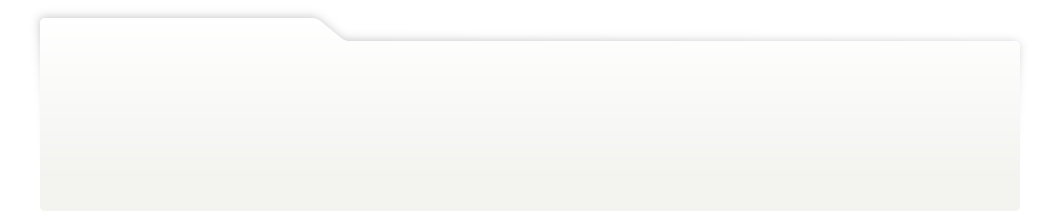
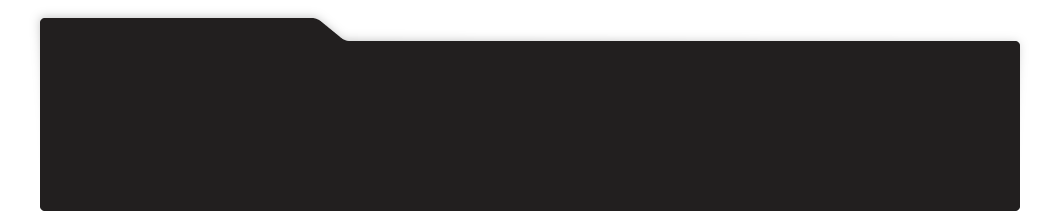
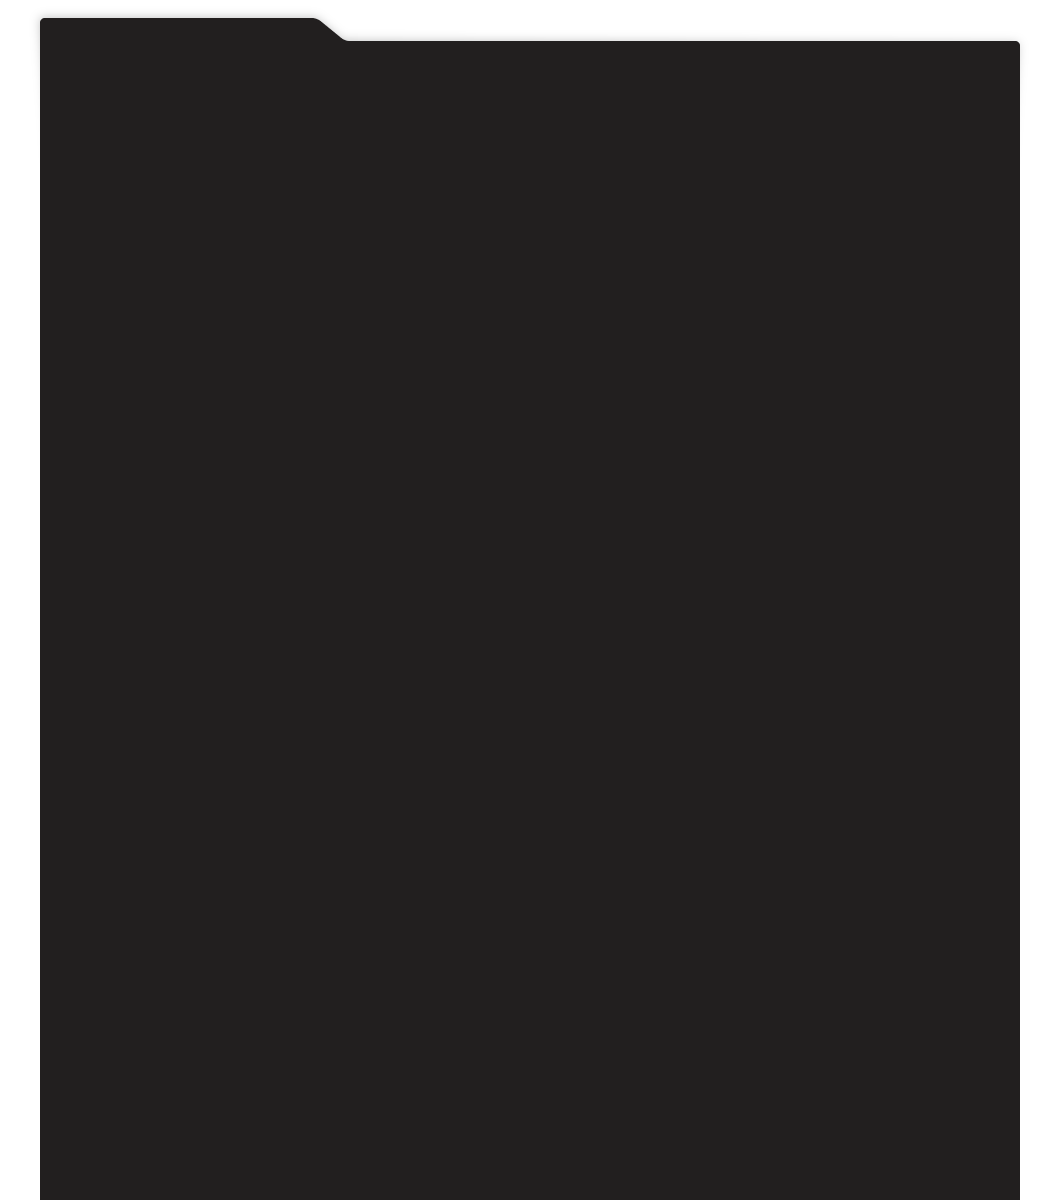
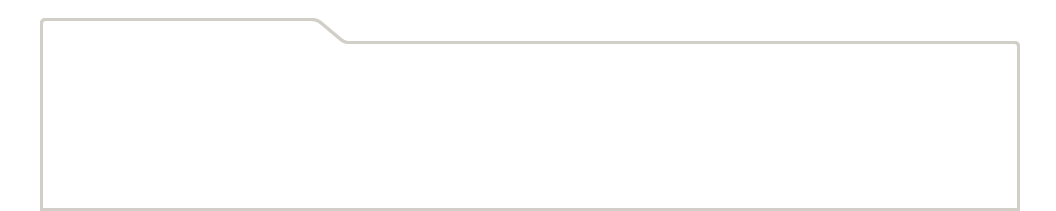
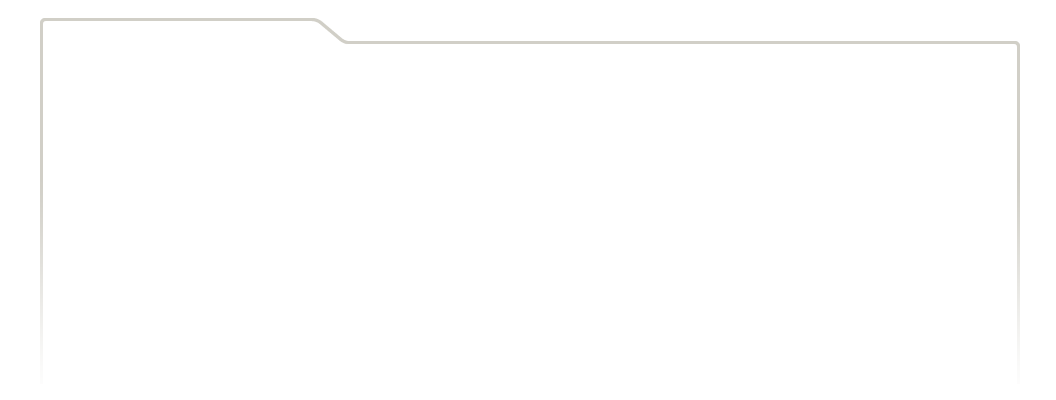
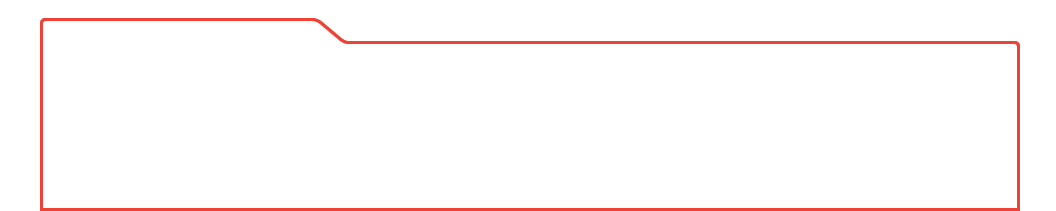
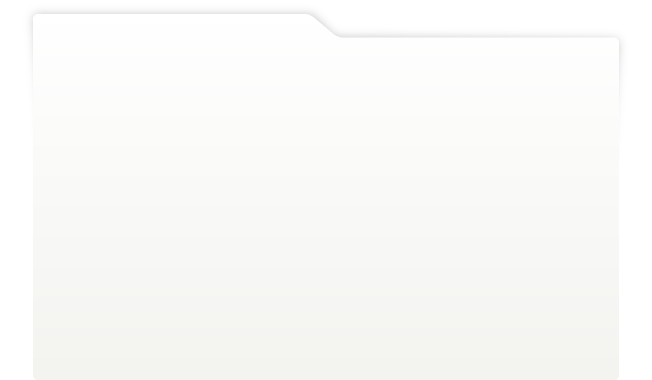
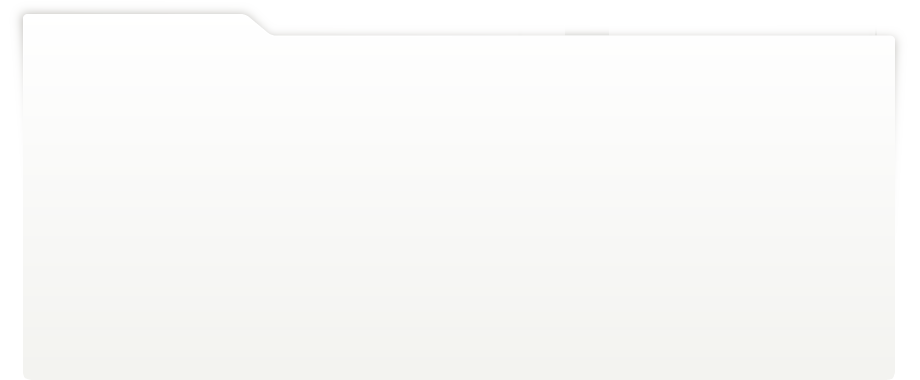
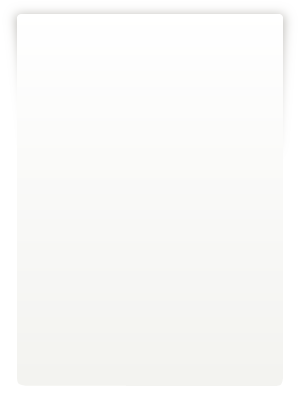
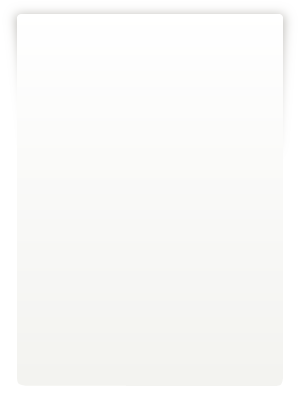
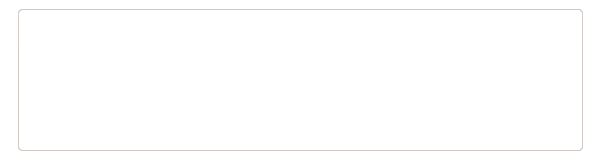
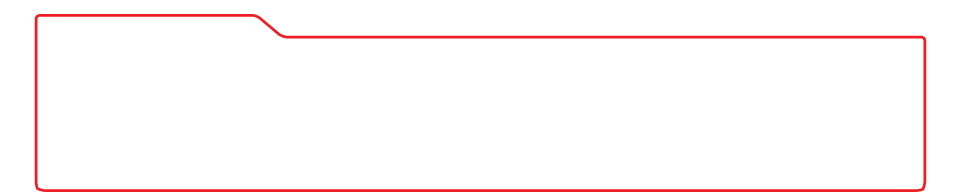
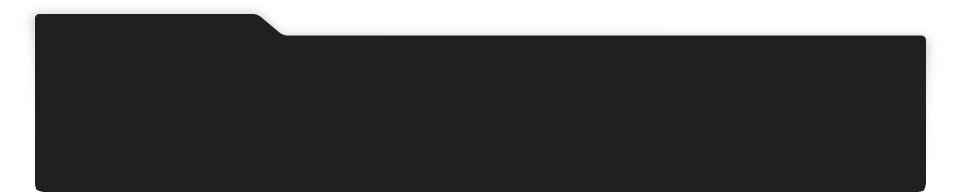
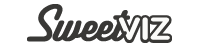
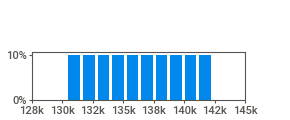
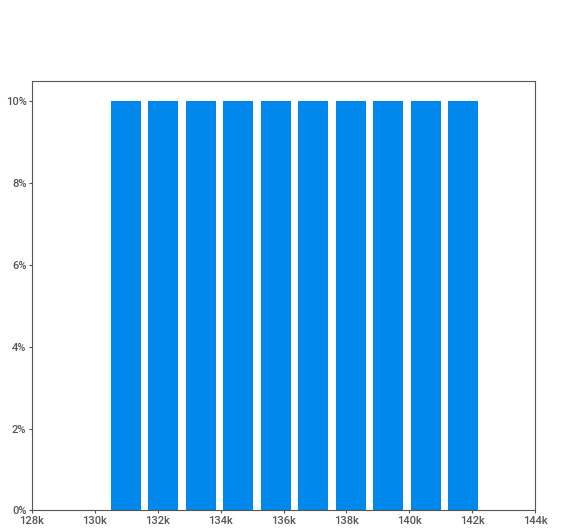
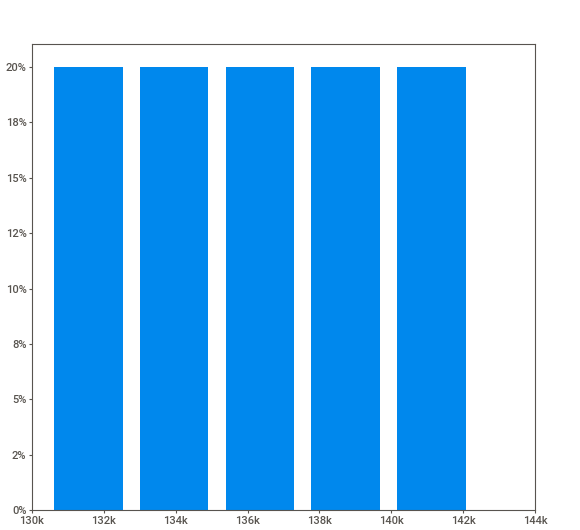
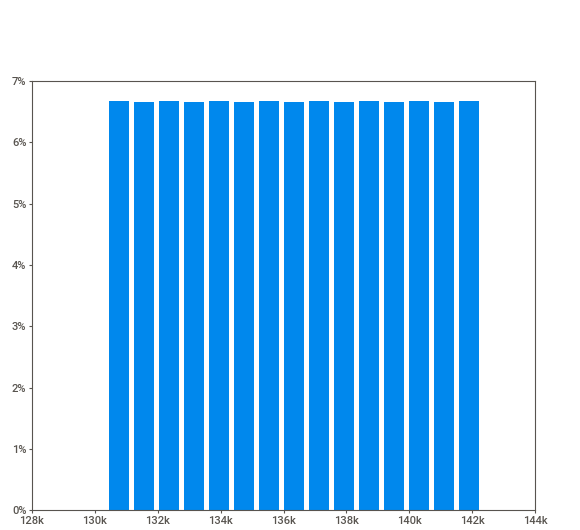
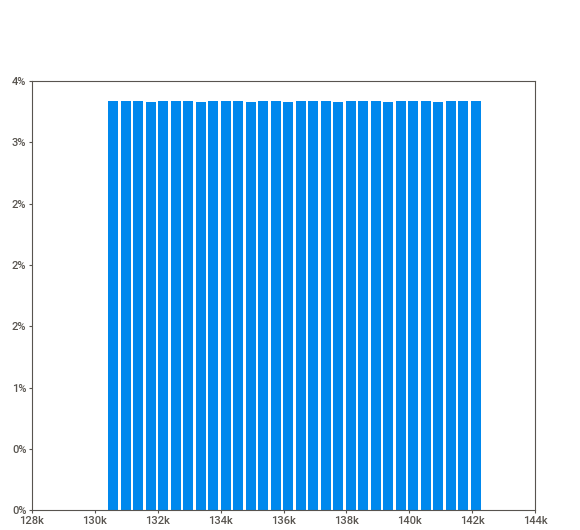
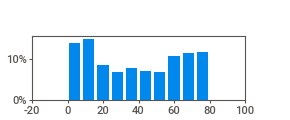
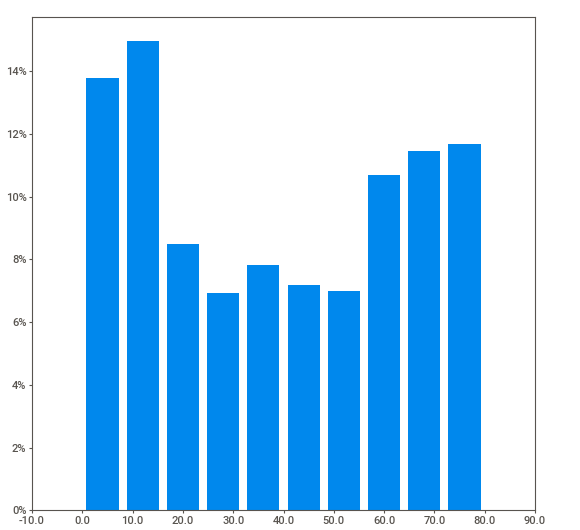
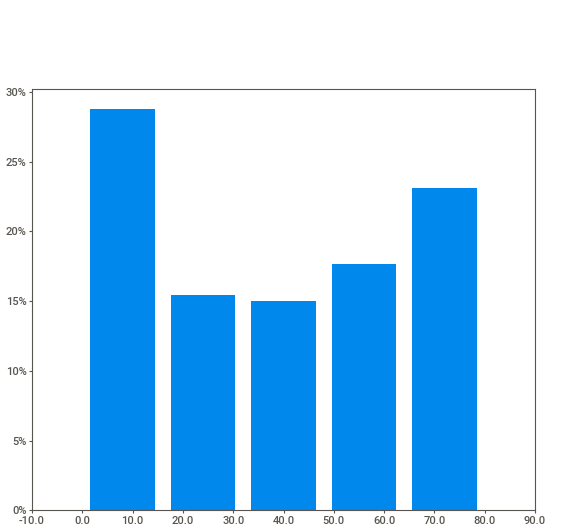
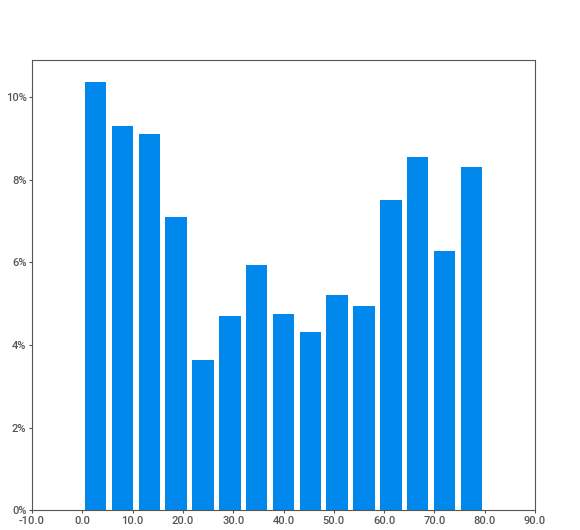
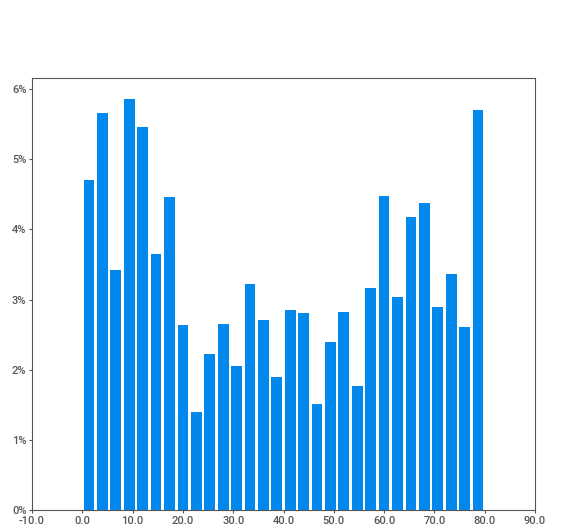
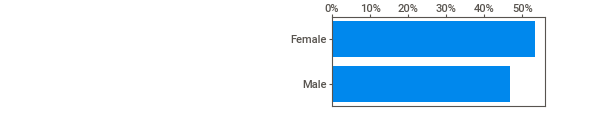
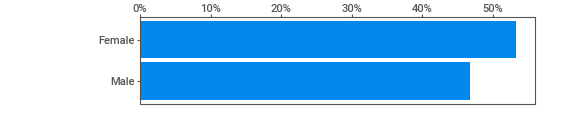
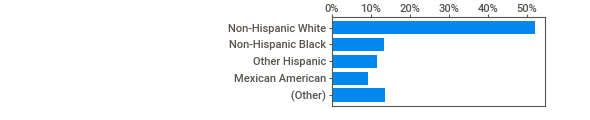
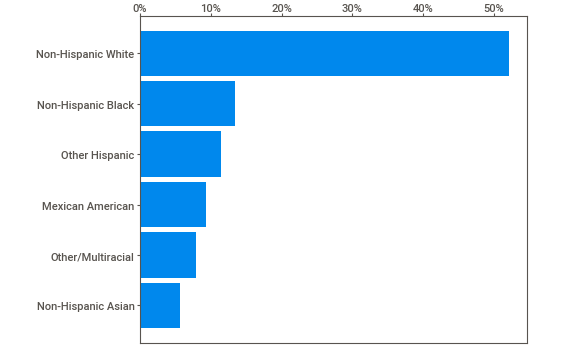
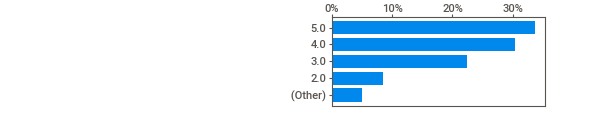
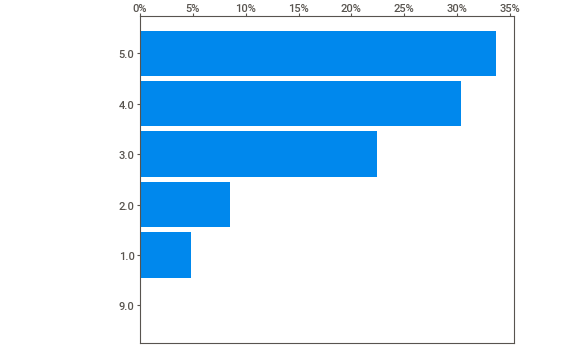
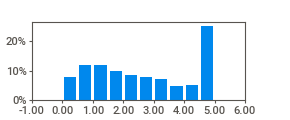
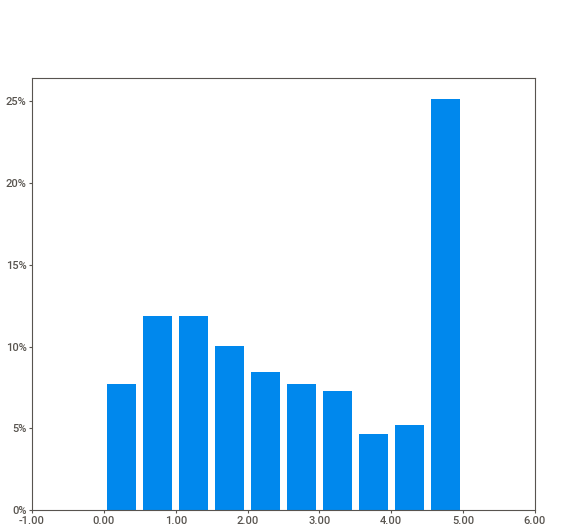
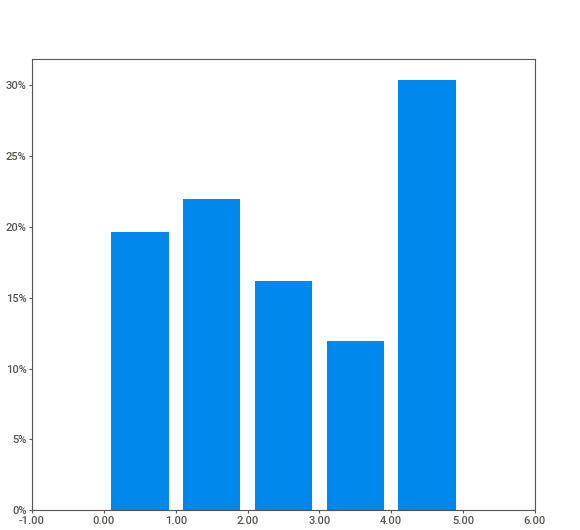
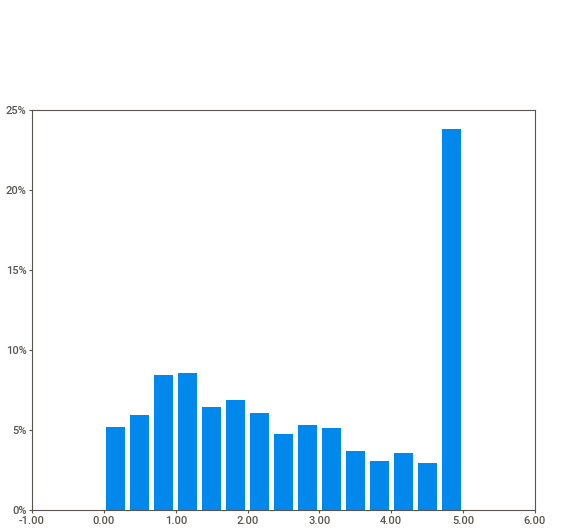
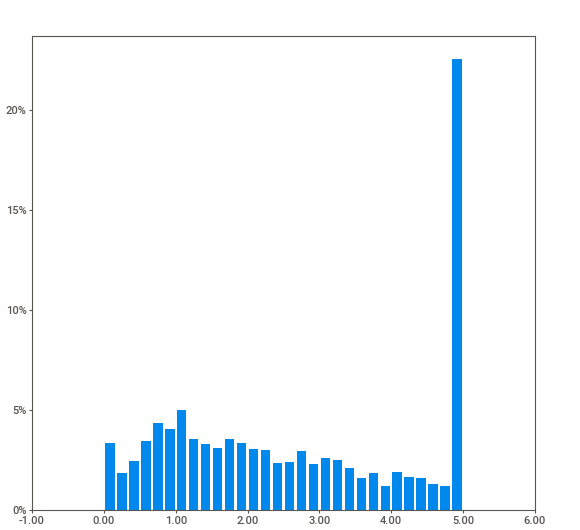
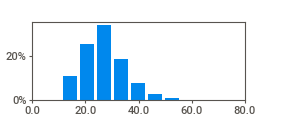
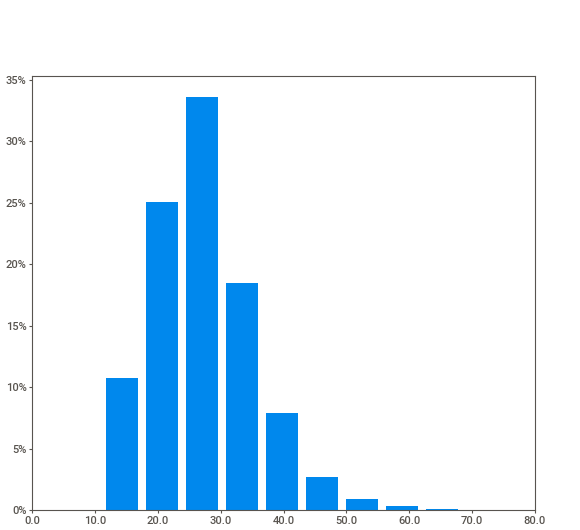
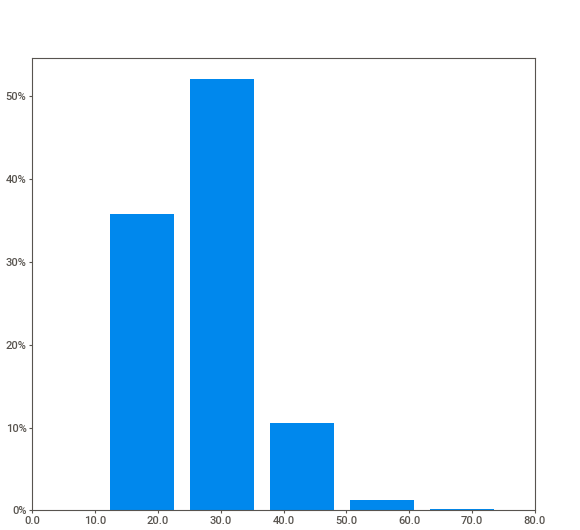
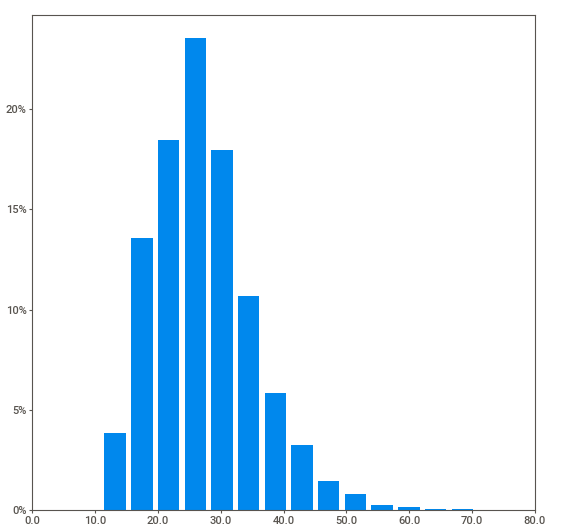
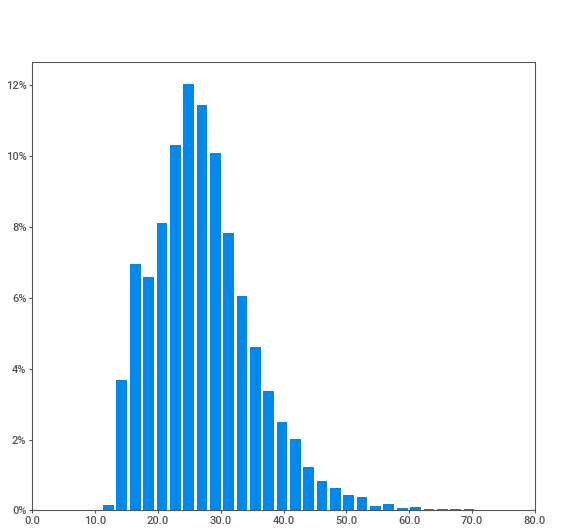
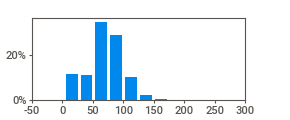
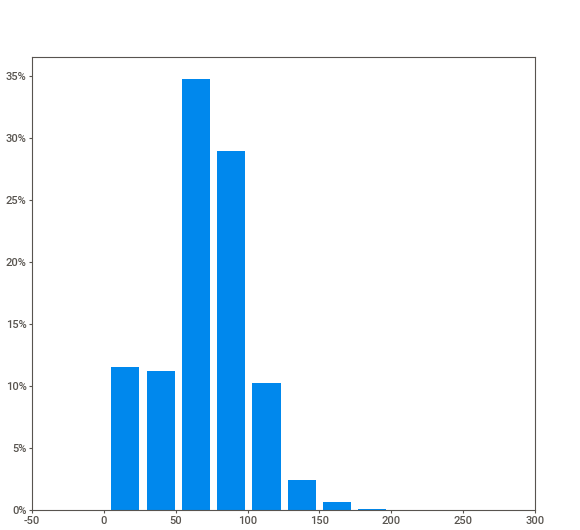
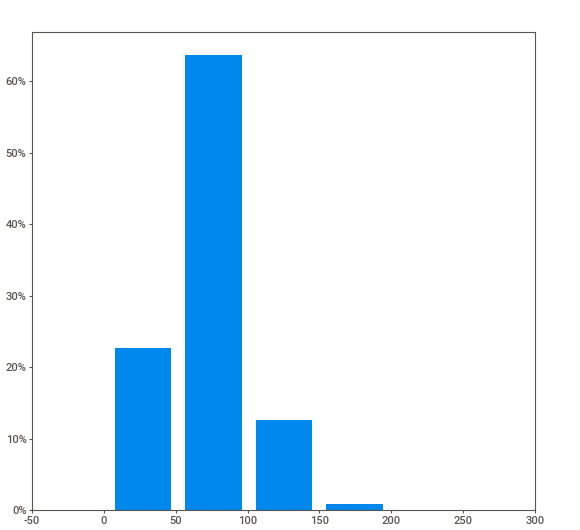
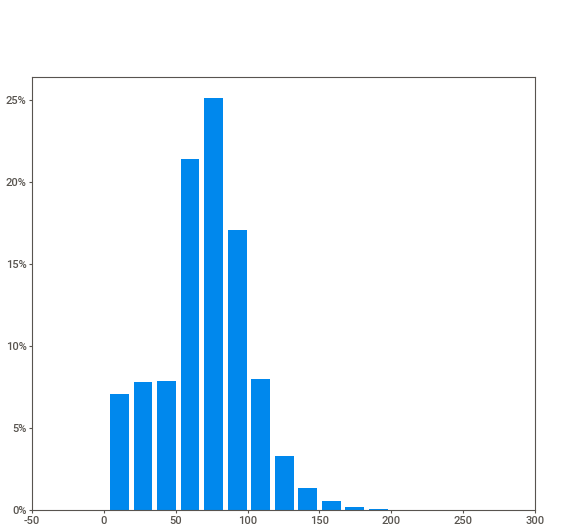
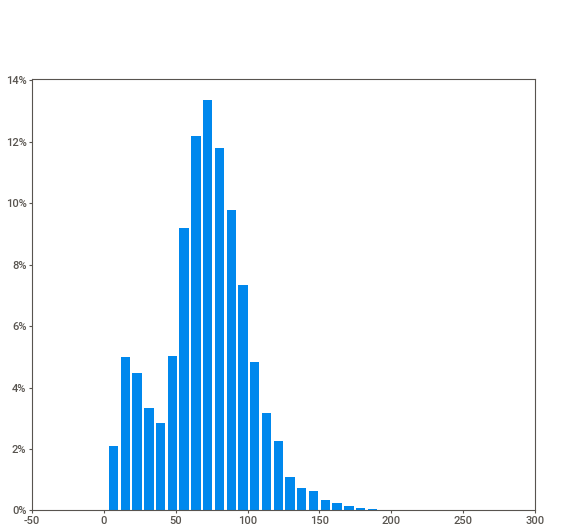
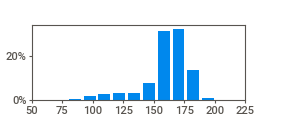
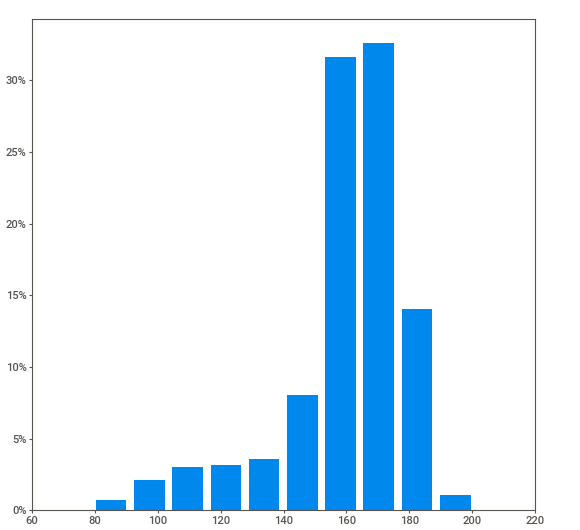
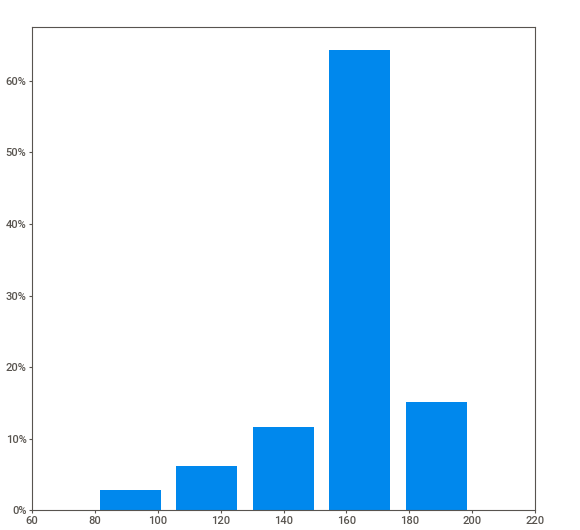
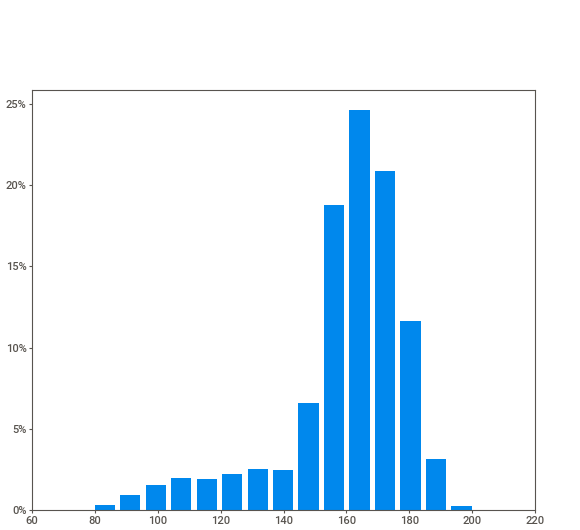
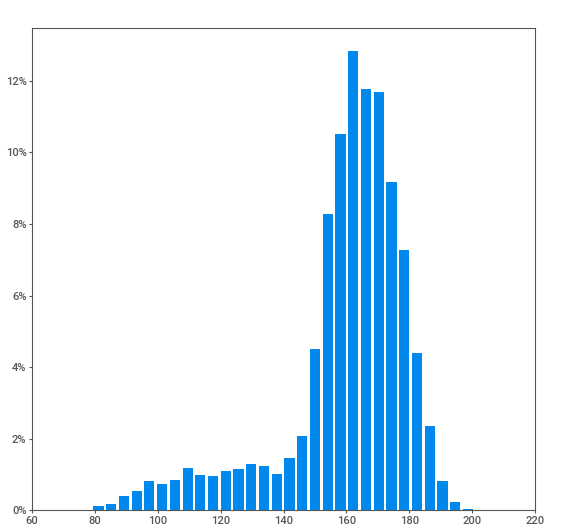
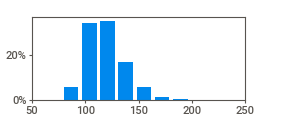
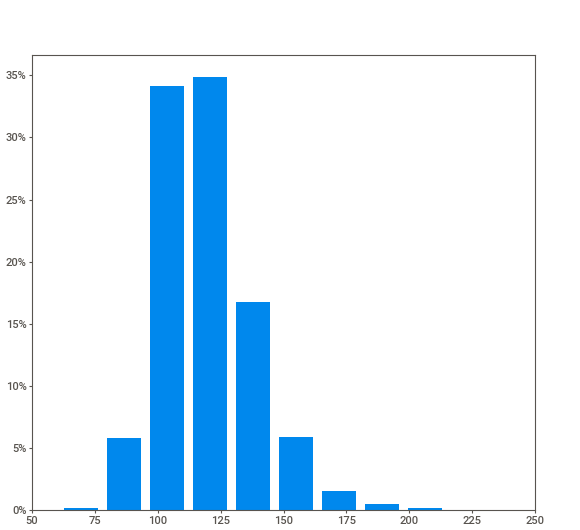
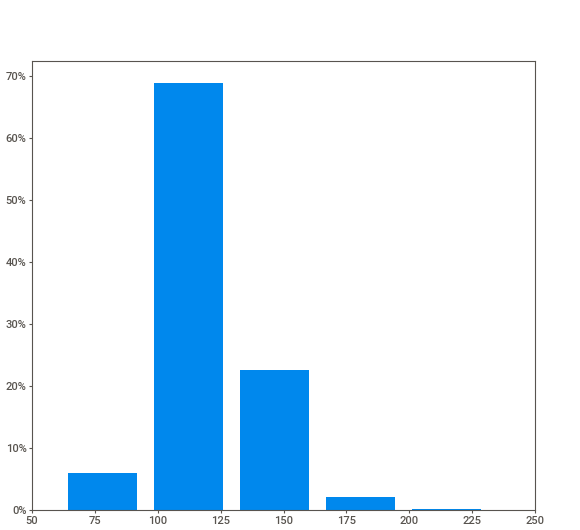
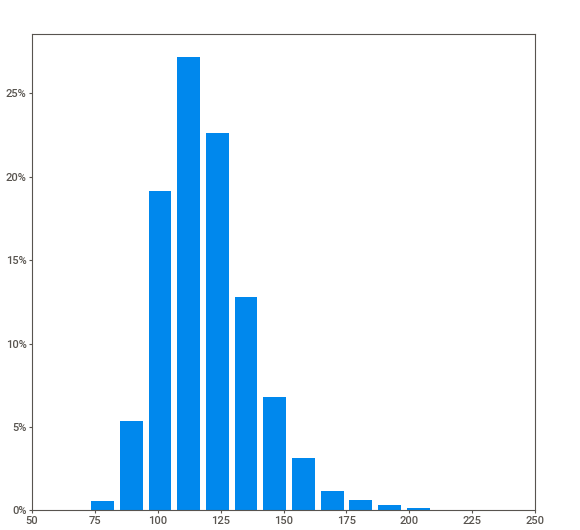
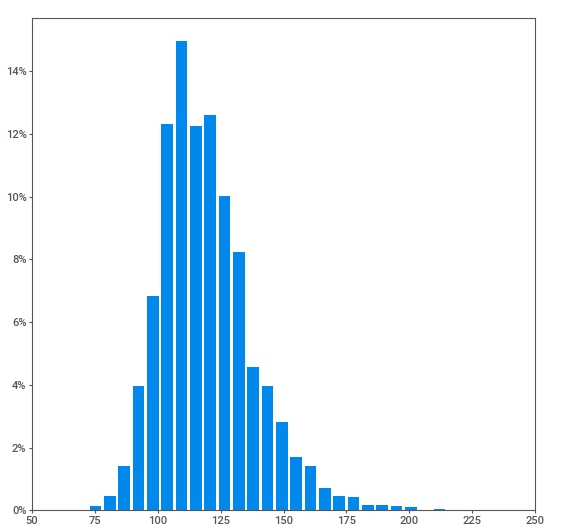
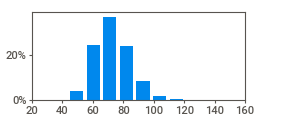
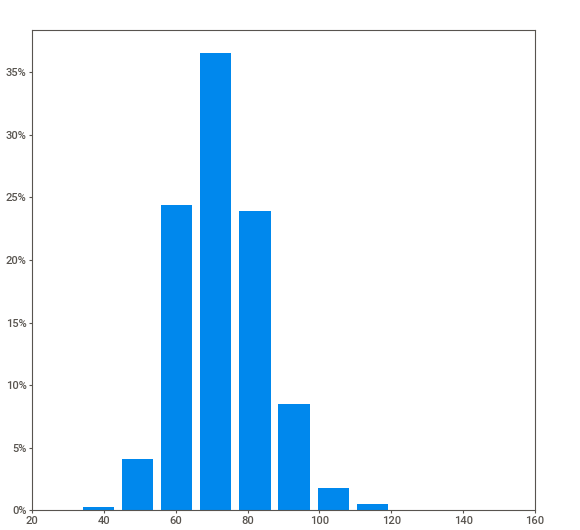
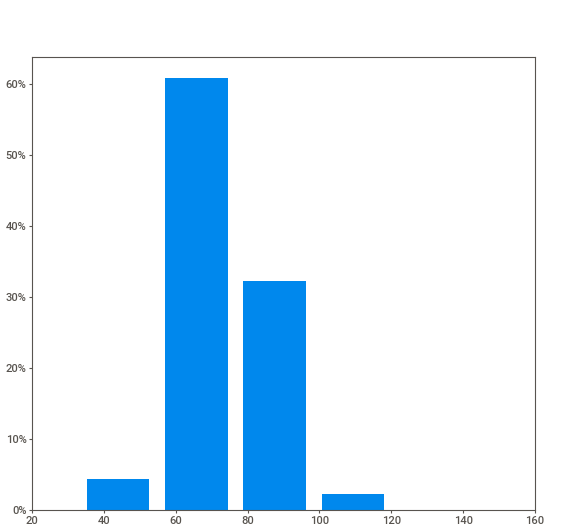
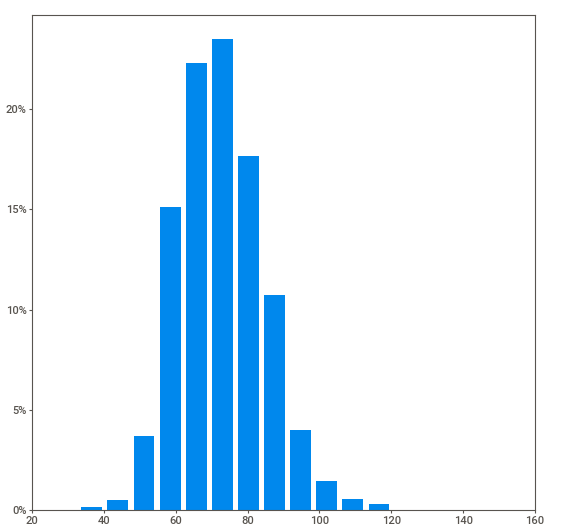
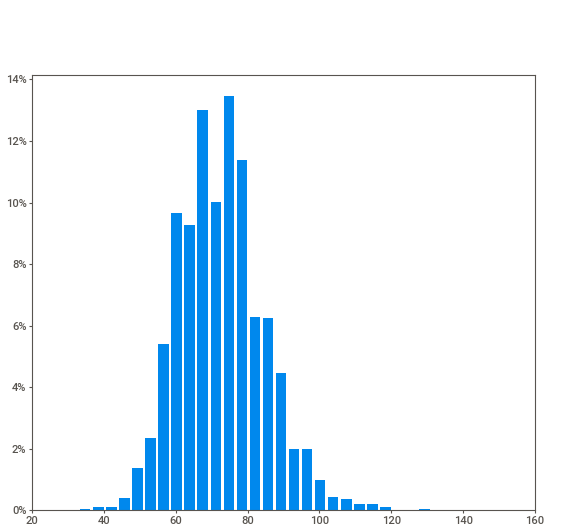
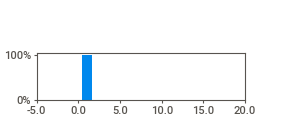
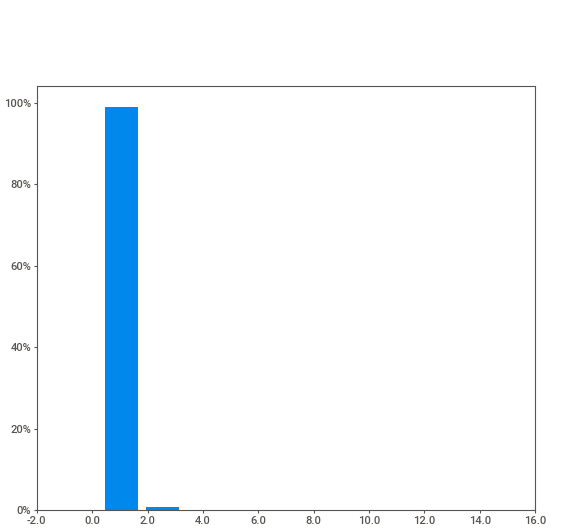
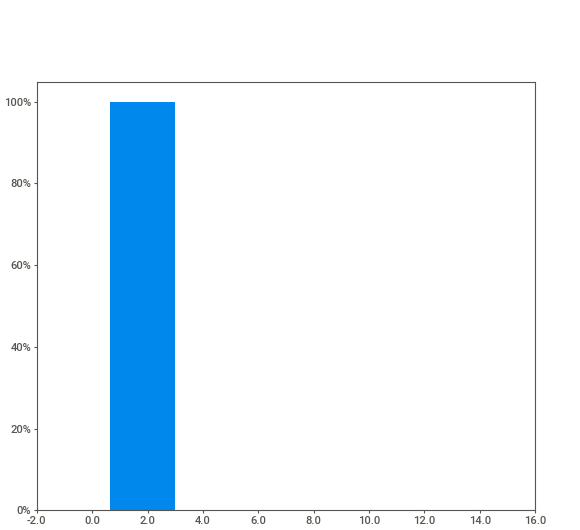
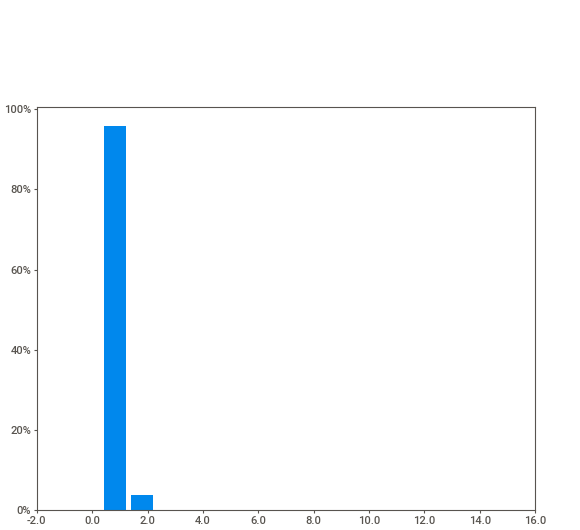
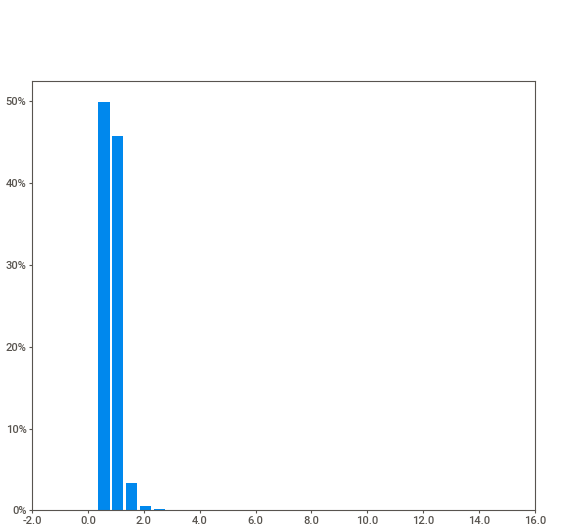
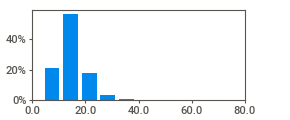
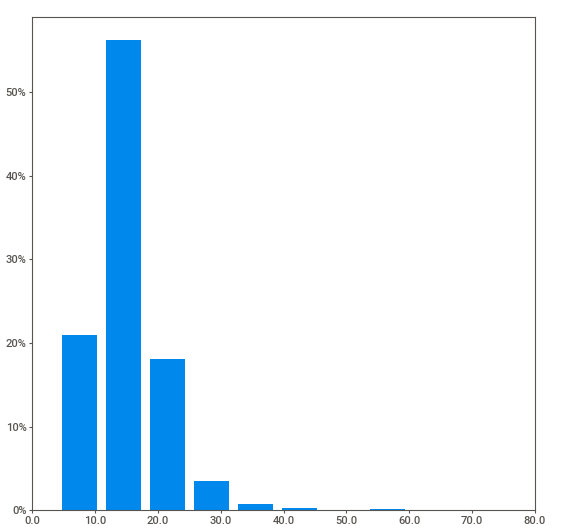
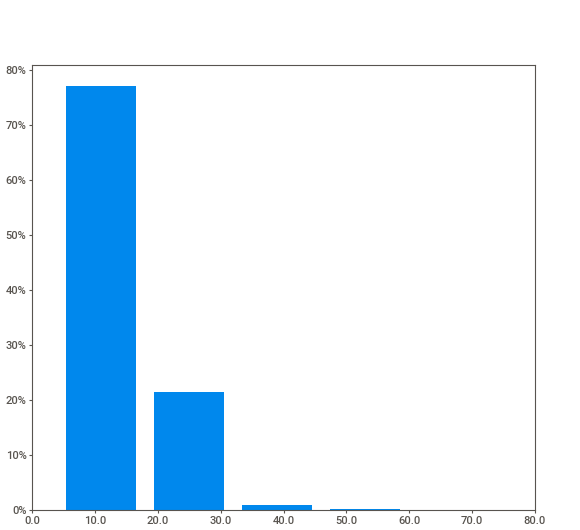
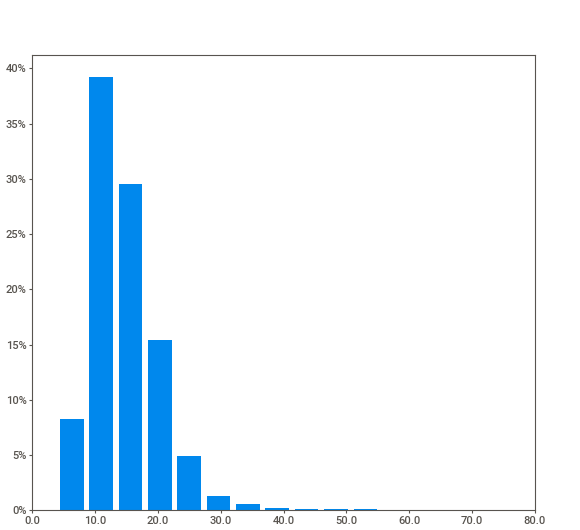
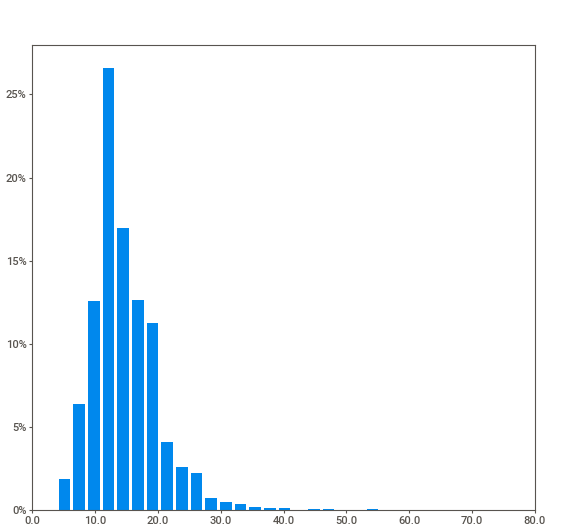
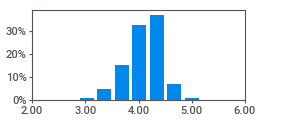
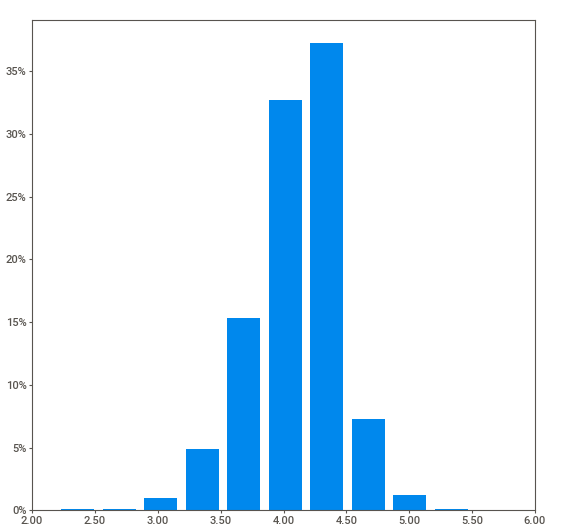
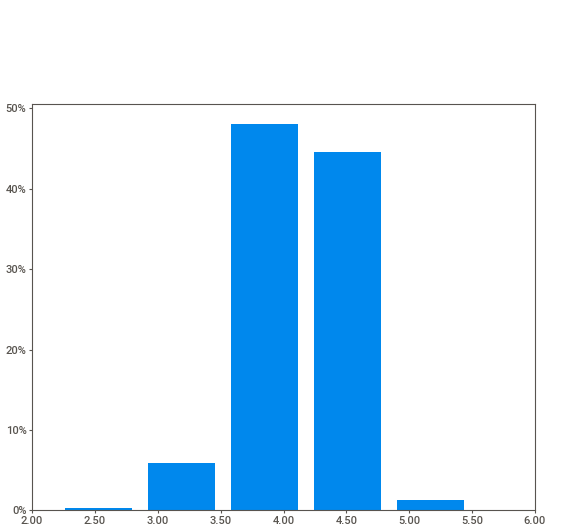
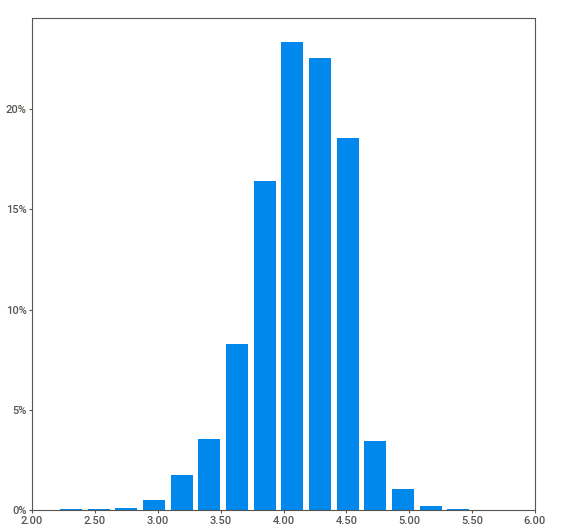
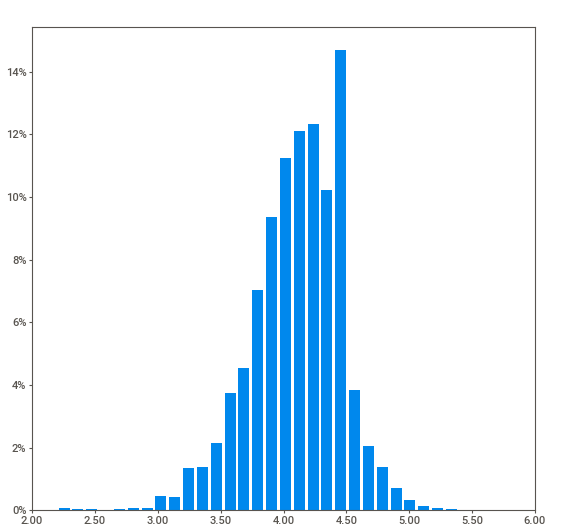
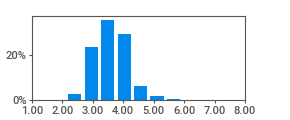
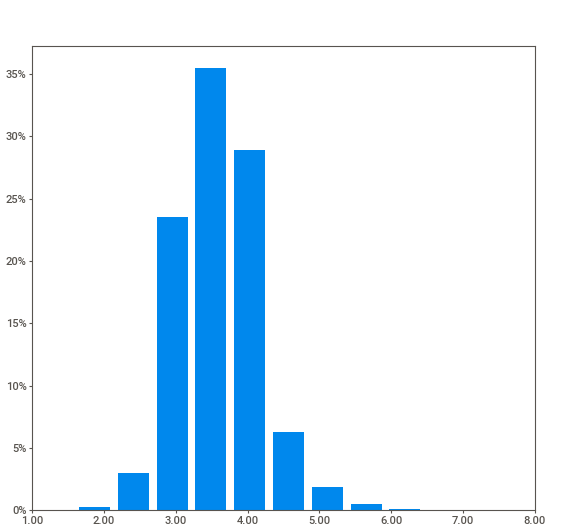
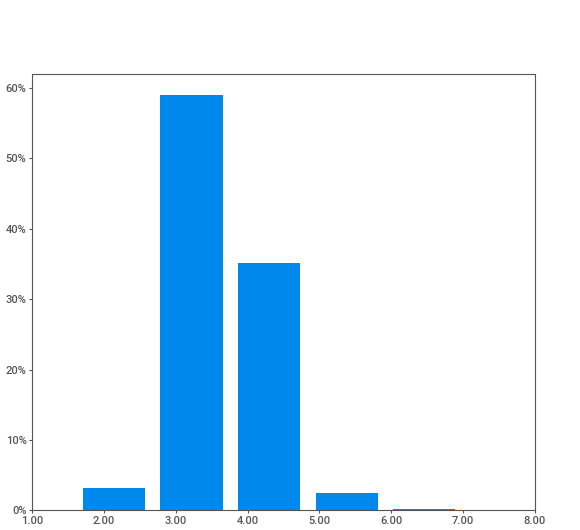
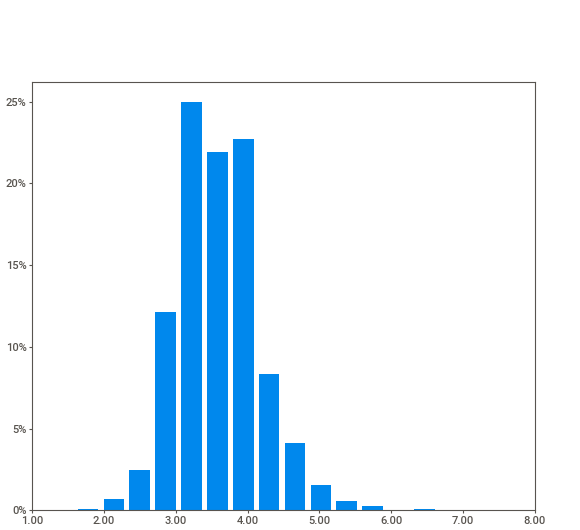
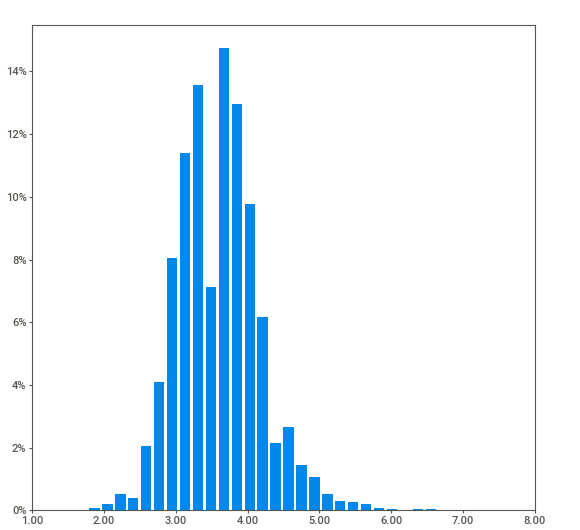
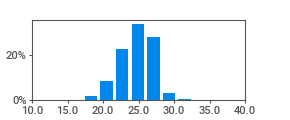
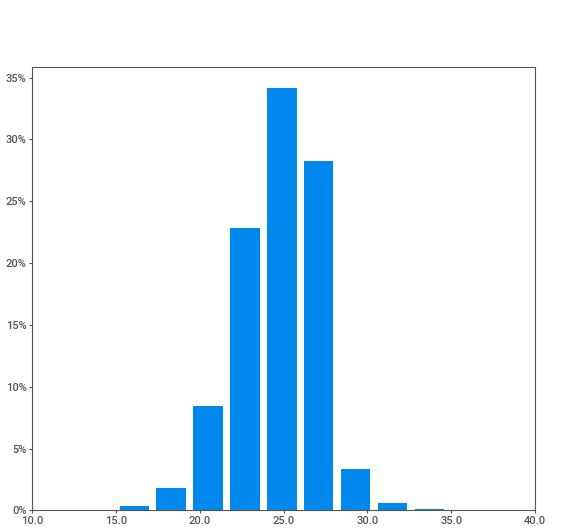
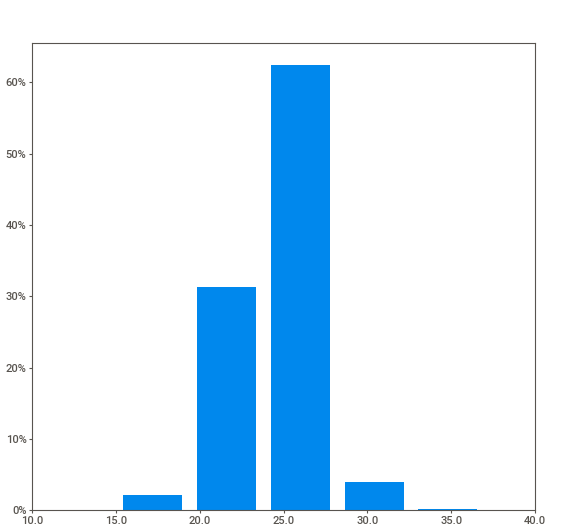
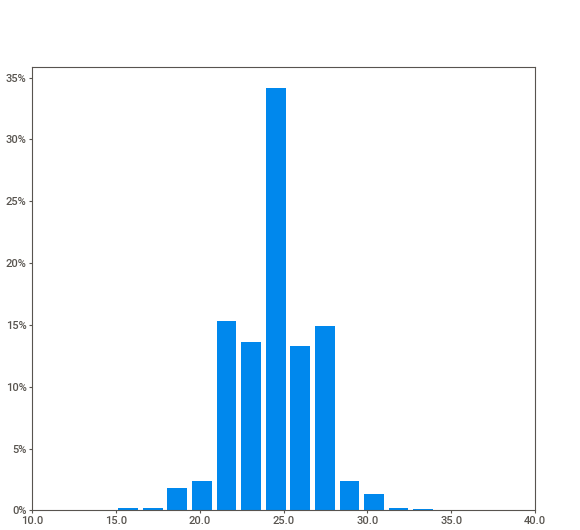
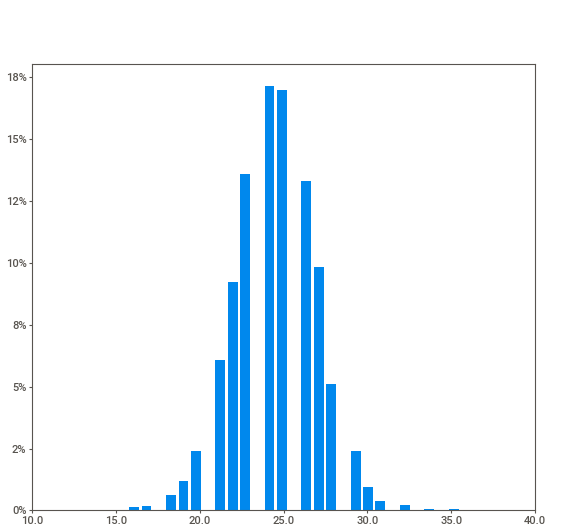
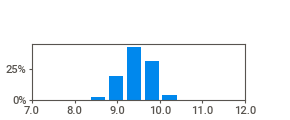
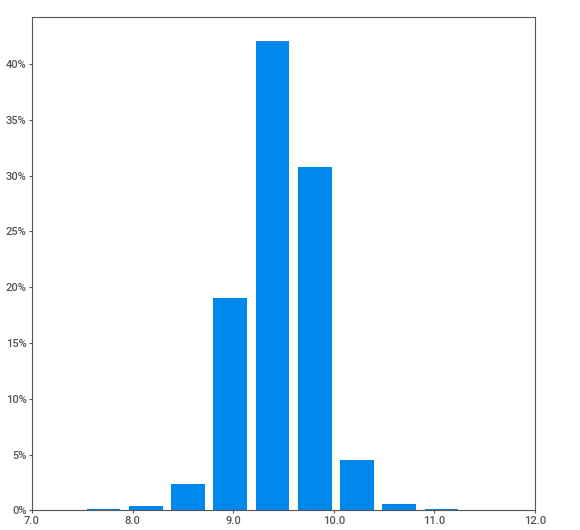
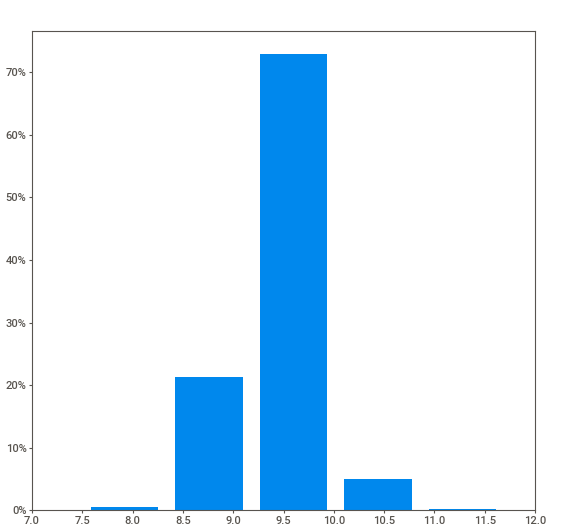
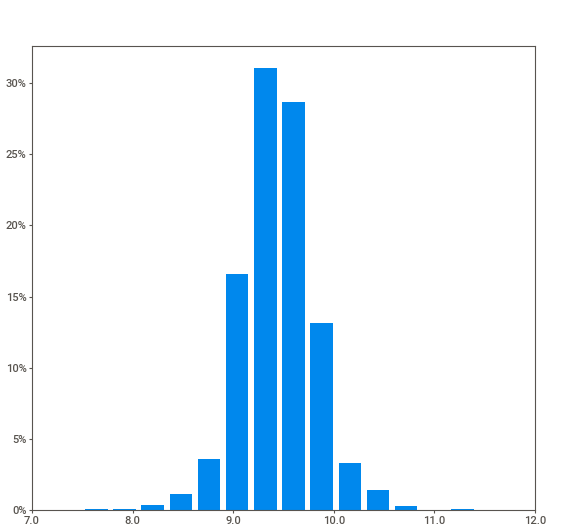
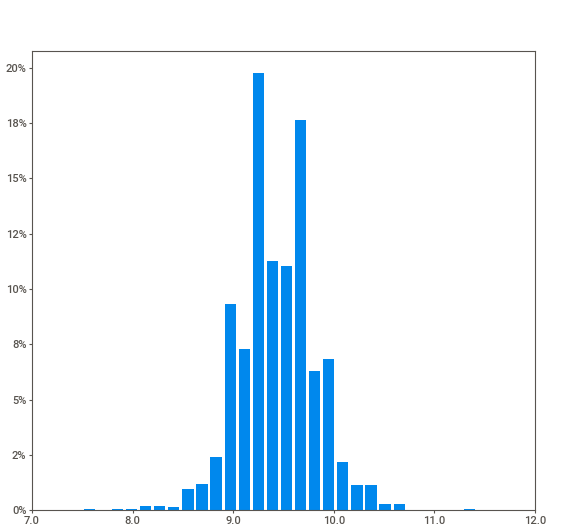
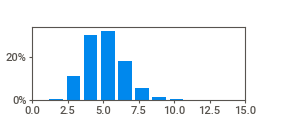
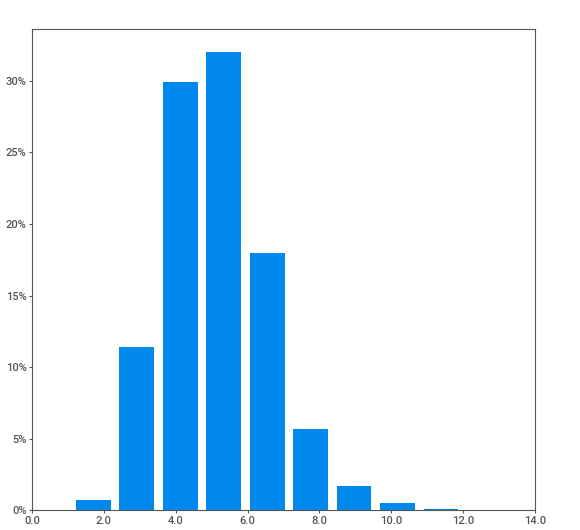
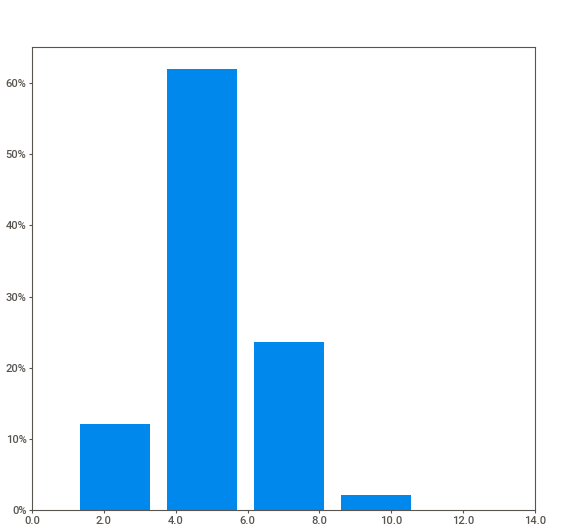
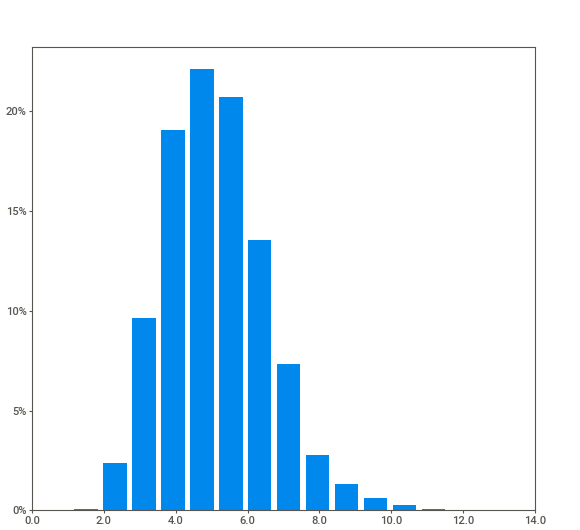
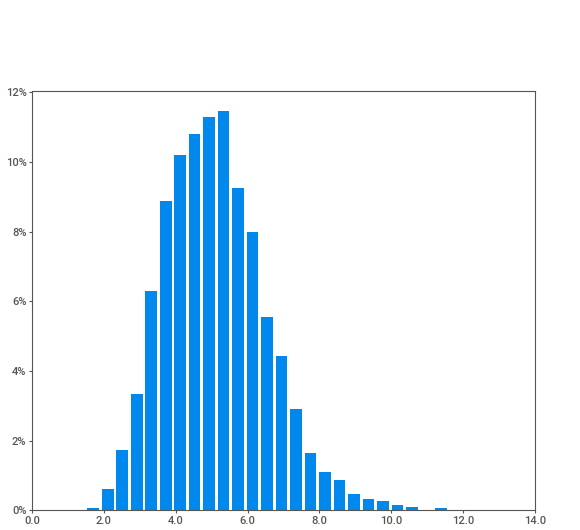
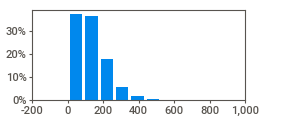
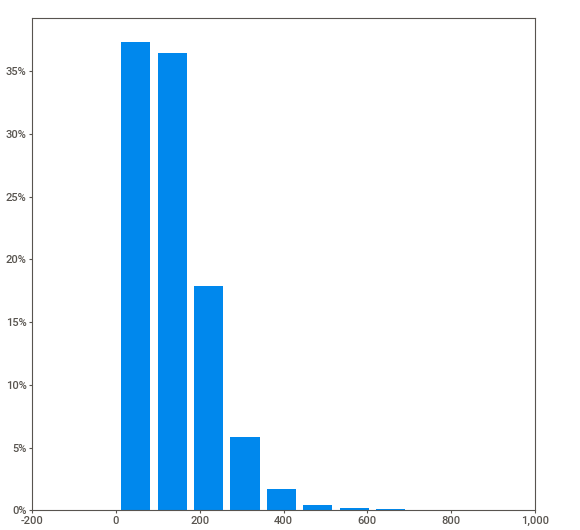
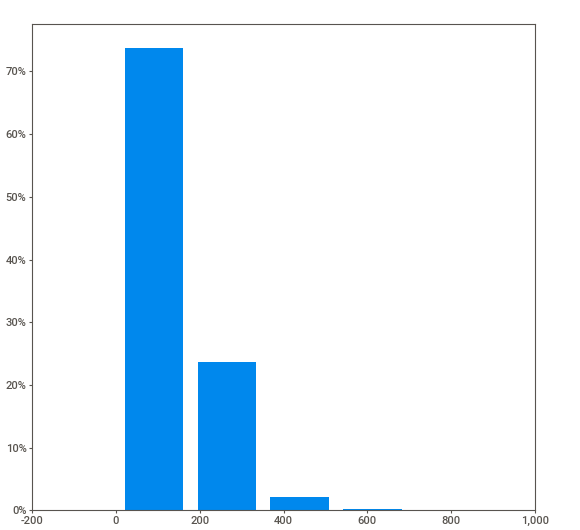
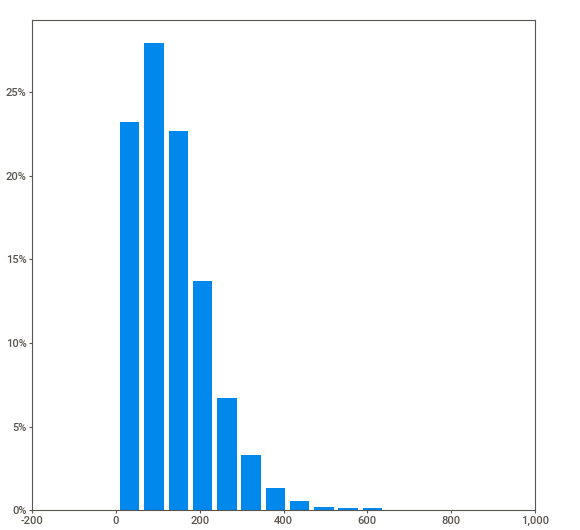
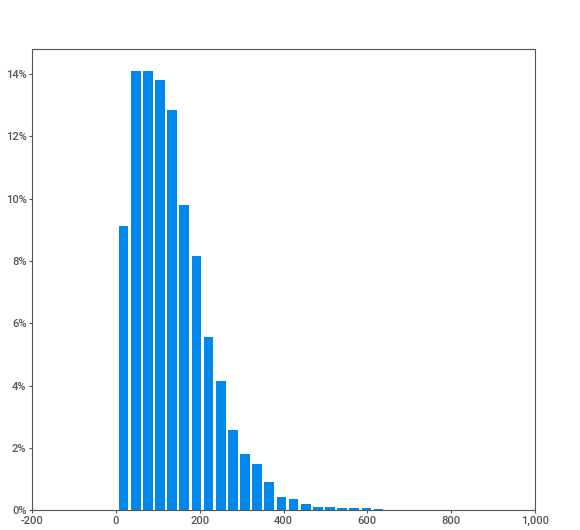
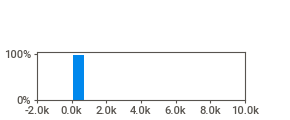
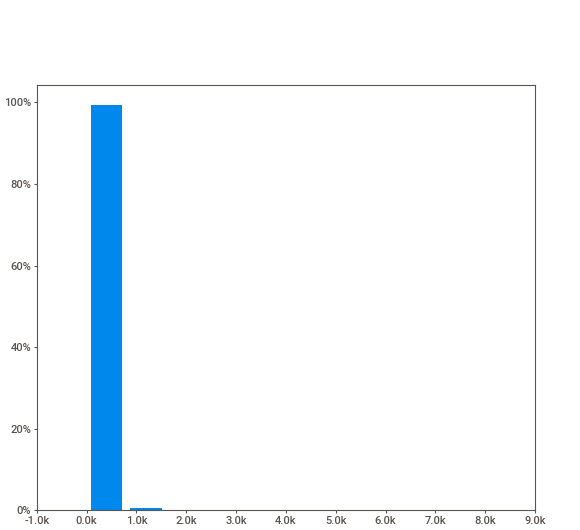
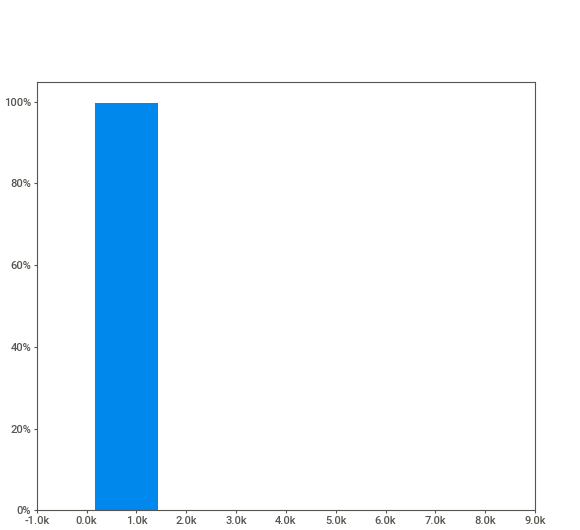
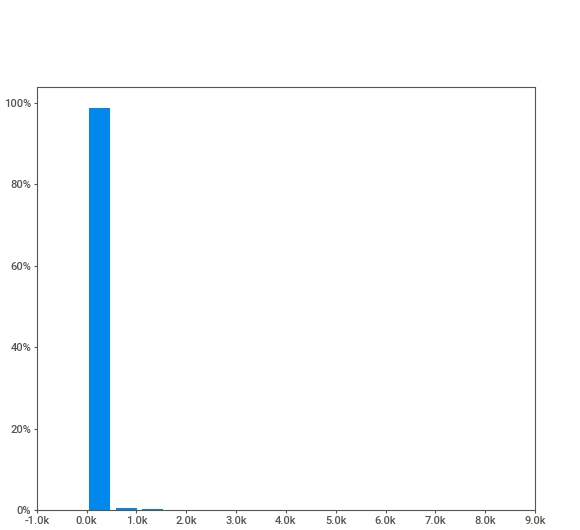
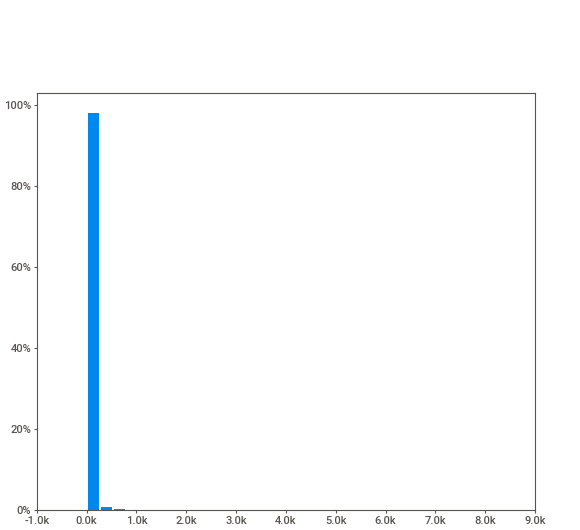
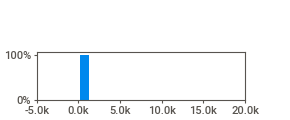
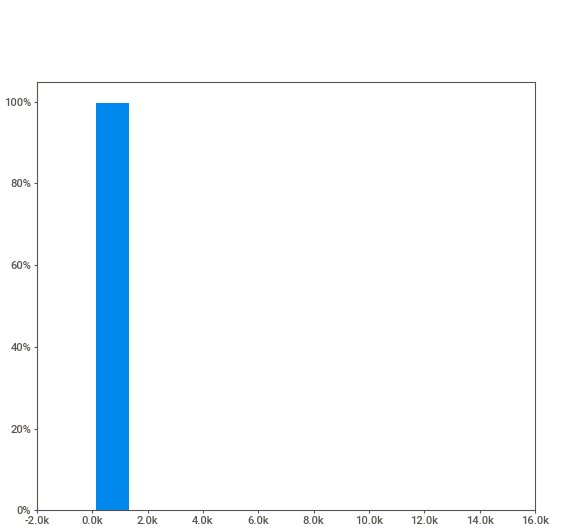
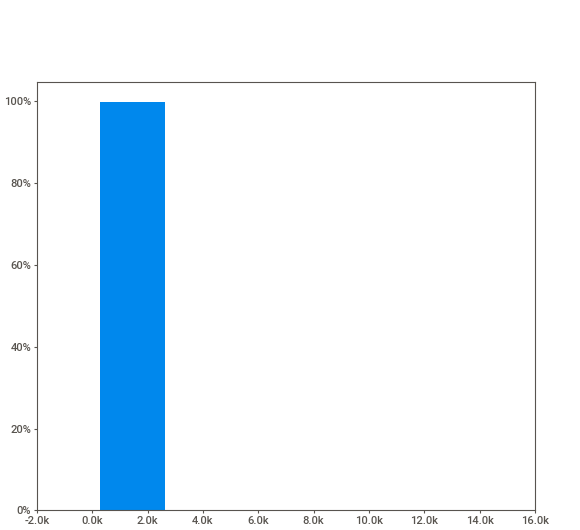
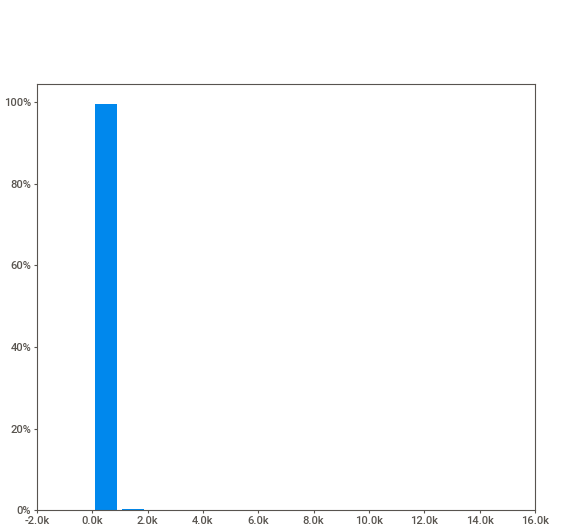
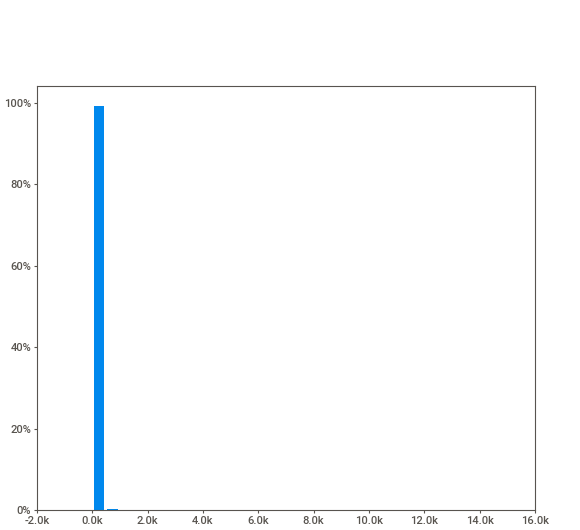
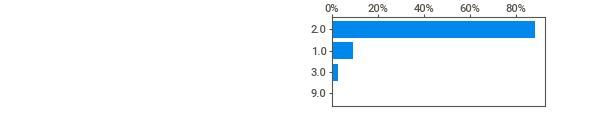
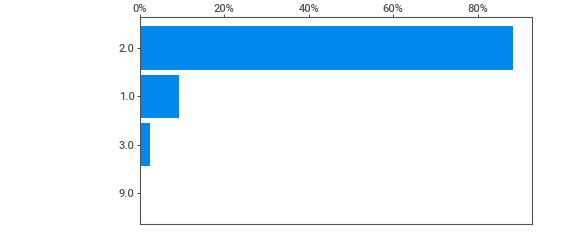
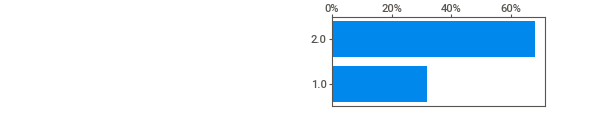
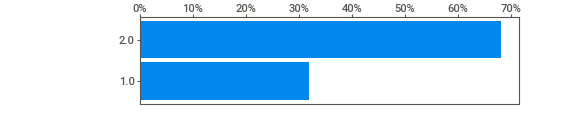
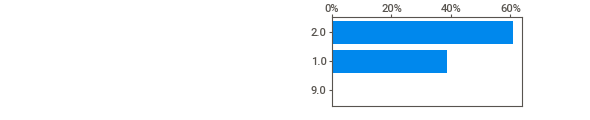
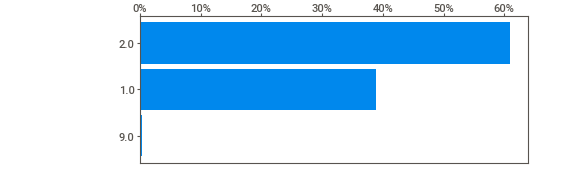
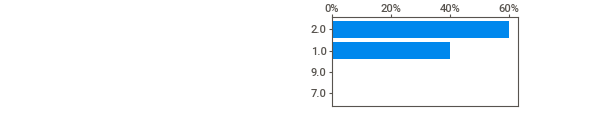
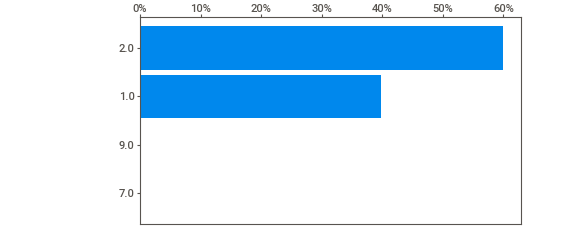
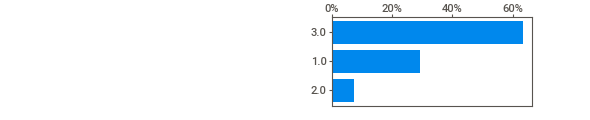
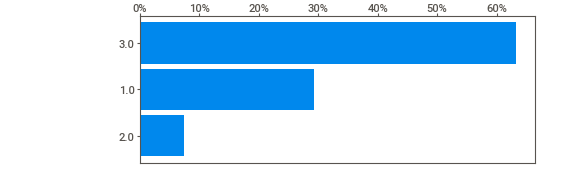
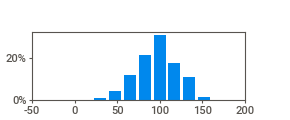
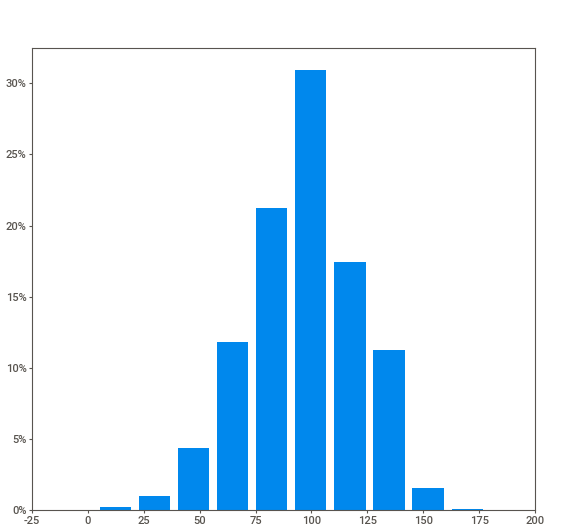
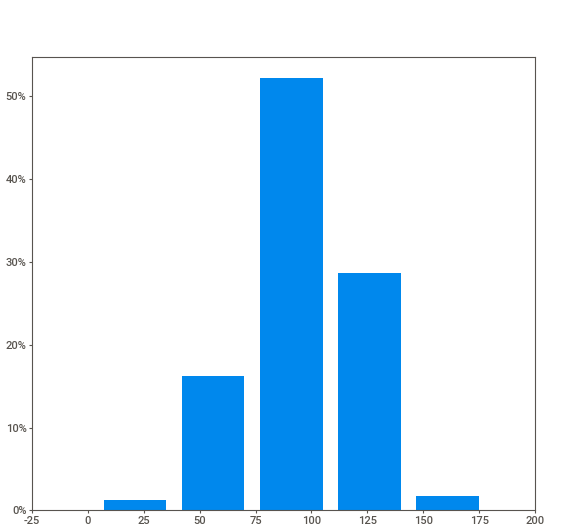
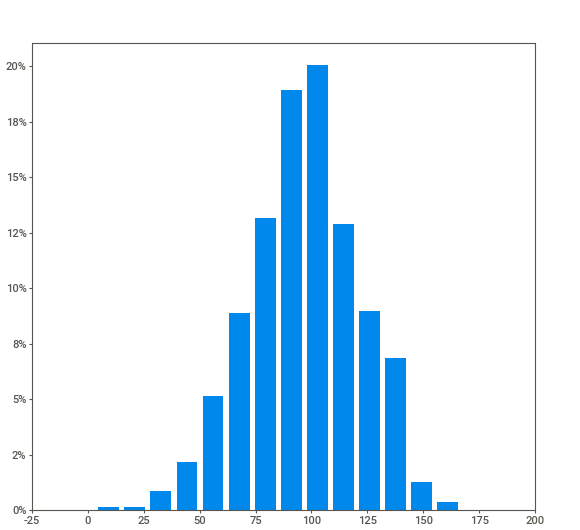
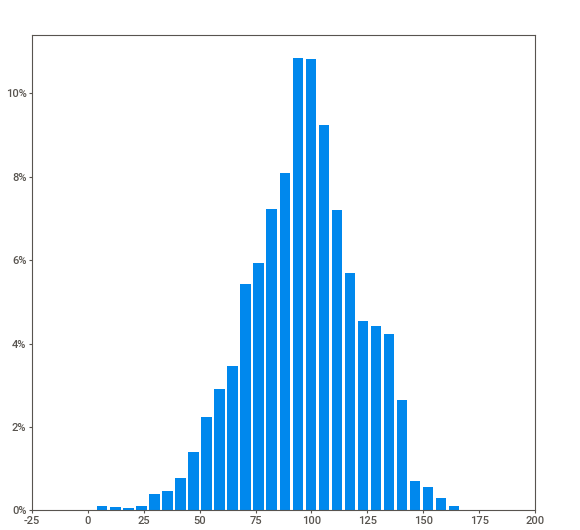
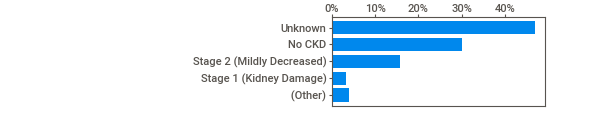
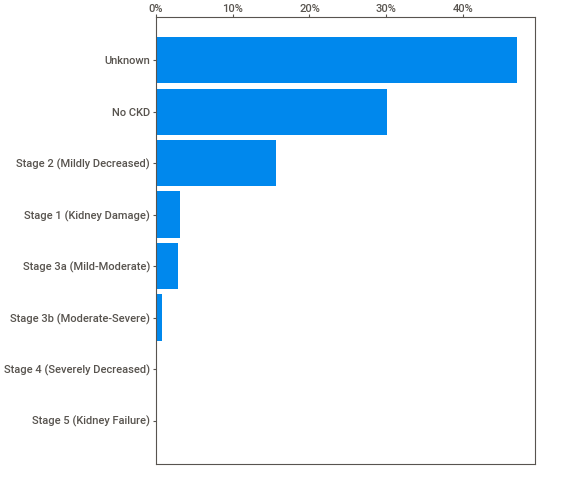
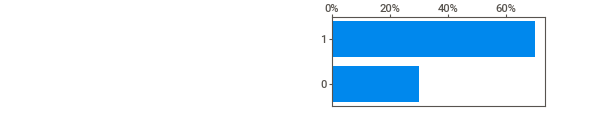
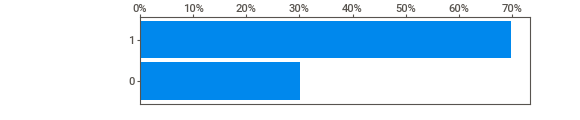
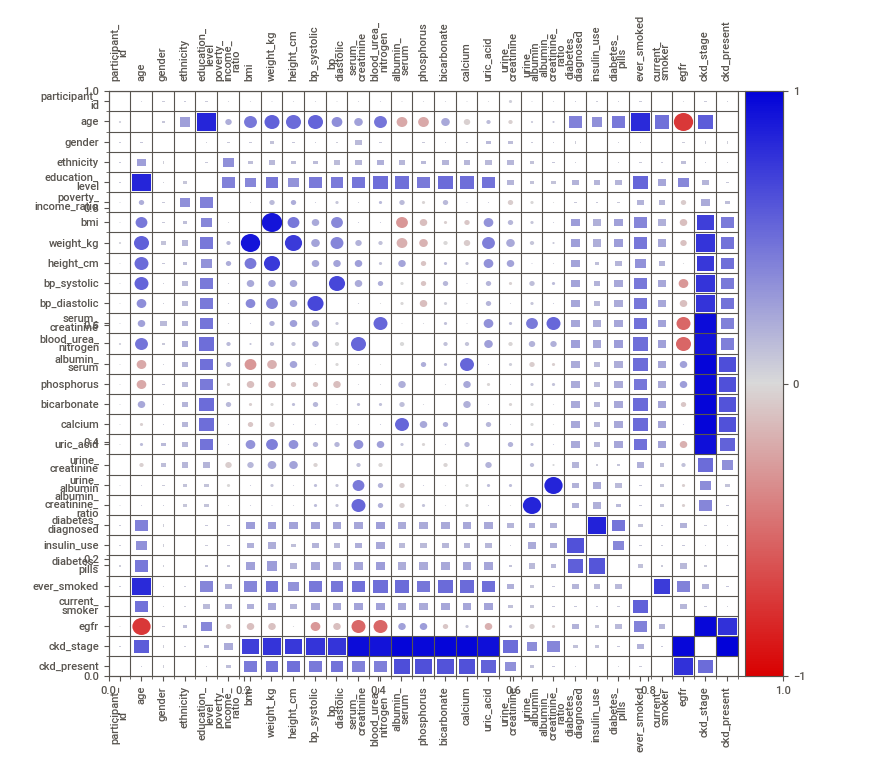
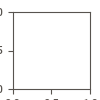

In [ ]:
import sweetviz as sv

reporte = sv.analyze(dataframe)
reporte.show_notebook()

Segunda Sección: Limpieza de la base


Hasta ahora se ha trabajado con el dataset tal cual aparece en el repositorio, pero para realizar un analisis de los datos es conveniente limpiarlo.
Es decir, tratamiento de valores nulos.

Limpieza preliminar: pasar todos los 7 y 9 a nulo porque indican unknown tambien en ckd present cambiar a nulo los que tiene ckd stage unknown porque a algun genio se le ocurrio poner unknown tambien como 1.

Para esto primero hay que entender si hay alguna razón subyacente por la que en una variable aparecen nulos.
Por ejemplo, las variables insulin_use y diabetes_pills se dejan nulas si diabetes_diagnosed es falso, lo mismo sucede con current_smoker y ever_smoked, por esto tienen un porcentaje tan alto de nulos. Cambiar por NO total ni tienen el precedente.



In [ ]:

import numpy as np
import pandas as pd

# Trabajamos sobre una copia para conservar el dataset original.
dataframe_limpieza = dataframe.copy()

# 1. Variables donde 7 y 9 representan "Unknown".
# Completar con las columnas confirmadas en el diccionario del dataset.
columnas_con_codigos_7_9 = [
    "education_level",
    "diabetes_diagnosed",
    "diabetes_pills",
    "ever_smoked",
]

for columna in columnas_con_codigos_7_9:
    dataframe_limpieza[columna] = dataframe_limpieza[columna].replace([7, 9], np.nan)

# 2. Tratar explícitamente los valores de texto "Unknown".
# Aplicar solo a las columnas donde corresponda.
columnas_con_unknown_textual = [
    "ckd_stage",
]

for columna in columnas_con_unknown_textual:
    dataframe_limpieza[columna] = dataframe_limpieza[columna].replace(
        r"(?i)^\s*unknown\s*$", np.nan, regex=True
    )

mask = (
    dataframe_limpieza["ckd_stage"].isna()
    & (dataframe_limpieza["ckd_present"] == 1)
)

dataframe_limpieza.loc[mask, "ckd_present"] = np.nan

# Resumen de faltantes después de la limpieza.
resumen_nulos = (
    dataframe_limpieza.isna()
    .sum()
    .to_frame("cantidad_nulos")
)

resumen_nulos["porcentaje_nulos"] = (
    dataframe_limpieza.isna().mean() * 100
).round(2)

display(
    resumen_nulos.sort_values(
        "porcentaje_nulos", ascending=False
    )
)


,cantidad_nulos,porcentaje_nulos
insulin_use,10852,90.94
diabetes_pills,9659,80.94
current_smoker,8690,72.82
phosphorus,5611,47.02
bicarbonate,5608,47.00
ckd_stage,5607,46.99
ckd_present,5607,46.99
egfr,5607,46.99
serum_creatinine,5607,46.99
blood_urea_nitrogen,5607,46.99


Viendo algunas filas del dataframe se ven personas que tienen casi todas las variables en nulo media pila vamos a ver cuantas

In [ ]:
# Proporción de valores faltantes por fila
dataframe["proporcion_null"] = dataframe.isnull().mean(axis=1)

# Cantidad de valores faltantes por fila
dataframe["cantidad_null"] = dataframe.isnull().sum(axis=1)

# Distribución de filas según proporción de faltantes
dataframe["proporcion_null"].describe()



,proporcion_null
count,11933.000000
mean,0.330561
std,0.266250
min,0.000000
25%,0.103448
50%,0.172414
75%,0.620690
max,0.793103


Lo voy a saltear por ahora porque no sé q hacer


La tercera sección también me la salteo las planteamo después


Cuarta sección: validación de hipótesis

# Pruebas de Hipótesis y Validación Estadística

Validar una hipótesis significa realizar una prueba estadística que aporte evidencia para sostener una afirmación, garantizando que el resultado responda a un patrón real de la población y no a la variabilidad aleatoria de una muestra particular.

---

## 1. Parámetros Fundamentales

* **Hipótesis Nula ($H_0$):** Hipótesis de "no efecto", no diferencia o independencia. Se asume cierta desde el inicio y es la que se intenta desmentir o refutar.
* **Hipótesis Alternativa o de Investigación ($H_1$):** Es la hipótesis complementaria que plantea la existencia de un efecto, diferencia o relación.
* **Toma de Decisión:** La hipótesis planteada se contrasta evaluando si existe evidencia suficiente para rechazar la hipótesis nula ($H_0$).

---

## 2. Errores, Significancia y Poder Estadístico

| Concepto | Definición / Interpretación |
| :--- | :--- |
| **Nivel de Significancia ($\alpha$)** | Probabilidad de cometer un **Error Tipo I** (falso positivo): rechazar $H_0$ cuando en realidad era cierta (afirmar que hay relación cuando no la hay). Típicamente se fija en $0.05$. |
| **Nivel de Confianza ($1 - \alpha$)** | Probabilidad de no rechazar $H_0$ cuando efectivamente es cierta (habitualmente $0.95$ o $95\%$). |
| **Error Tipo II ($\beta$)** | Probabilidad de cometer un falso negativo: no rechazar $H_0$ cuando en realidad era falsa. |
| **Poder Estadístico ($1 - \beta$)** | Probabilidad de rechazar $H_0$ cuando es efectivamente falsa (capacidad del test para detectar un efecto real). |

---

## 3. Estadístico de Prueba y $p$-valor

Al aplicar una prueba estadística se ubica el resultado de la muestra dentro de la distribución teórica del test, obteniendo el **$p$-valor**:

> **$p$-valor:** Es la probabilidad de obtener un estadístico de prueba tan o más extremo que el observado en la muestra, asumiendo que la hipótesis nula ($H_0$) es verdadera.

### Criterio de Decisión Reglado:
* **Si $p$-valor $> \alpha$:** **No hay evidencia suficiente para rechazar $H_0$**. La probabilidad de obtener un valor extremo por simple azar muestral es mayor al límite tolerado.
* **Si $p$-valor $\le \alpha$:** **Existe evidencia suficiente para rechazar $H_0$** en favor de la hipótesis alternativa ($H_1$).

---

## 4. Elección de la Prueba Estadística y Supuestos

La validez del test depende de verificar los supuestos que exigen las variables analizadas:

1. **Tipo de variables:** Determinar si las variables involucradas son numéricas (continuas/discretas) o categóricas (nominales/ordinales).
2. **Distribución de los datos:** Evaluar si las variables numéricas cumplen el supuesto de **normalidad**.
3. **Homocedasticidad:** Para análisis multivariados o comparaciones de grupos, verificar si las variables presentan homogeneidad de varianzas (mismo desvío estándar).

---

## 5. Flujo de Trabajo Común

1. **Plantear la hipótesis** de investigación.
2. **Formular formalmente la hipótesis nula ($H_0$) y la hipótesis alternativa ($H_1$)**.
3. **Determinar el nivel de significancia ($\alpha$)** (ej. $0.05$).
4. **Estudiar las variables involucradas** (tipo de dato, normalidad, homocedasticidad) para seleccionar la prueba estadística adecuada.
5. **Ejecutar la prueba estadística** sobre los datos.
6. **Evaluar el $p$-valor** contra $\alpha$ para concluir sobre la validez de la hipótesis.





## 1. Hipótesis univariada: media de la relación albúmina-creatinina urinaria (ACR)

La primera hipótesis busca evaluar si la media de la ACR de los participantes supera los 30 mg/g, valor a partir del cual se considera que existe albuminuria aumentada según los criterios clínicos de KDIGO.

Los valores de referencia para la ACR se clasifican habitualmente de la siguiente manera:

### Formulación de las hipótesis

$$
H_0: \mu_{\mathrm{ACR}} \leq 30 \text{ mg/g}
$$

$$
H_1: \mu_{\mathrm{ACR}} > 30 \text{ mg/g}
$$

### Metodología de análisis

Se evaluará la normalidad mediante el test de Shapiro-Wilk y un QQ-plot.

Rara contrastar la media poblacional con el valor de referencia:
- **Test t de una muestra** o **Test de Wilcoxon** si la distribución presenta desviaciones importantes de la normalidad.

**Limitación:** el valor de 30 mg/g es un umbral clínico utilizado para clasificar mediciones individuales, no un objetivo recomendado para la media poblacional.

## 2. Hipótesis bivariada: relación entre el BMI y la diabetes diagnosticada

La segunda hipótesis busca estudiar si existe una relación entre el índice de masa corporal y la presencia de diabetes diagnosticada.

**Hipótesis de investigación:** el BMI medio de los participantes con diabetes diagnosticada es mayor que el BMI medio de los participantes sin diabetes diagnosticada.

Hipótesis:

$$
H_0: \mu_{\text{diabetes}} \leq \mu_{\text{sin diabetes}}
$$

$$
H_1: \mu_{\text{diabetes}} > \mu_{\text{sin diabetes}}
$$

Se evaluarán los supuestos estadísticos correspondientes:

1. **Normalidad:** se utilizará el test de Shapiro-Wilk y un QQ-plot.

2. **Homocedasticidad:** se aplicará el test de Levene.

A partir de estos resultados, se seleccionará el test de comparación de medias:

- **Test t de Student para muestras independientes** o **Test t de Welch** si no se puede asumir homocedasticidad.

## 3. Hipótesis multivariada: Relación entre los parámetros bioquímicos sanguíneos y la función renal

Se analizará la relación entre parámetros sanguíneos y la tasa de filtración glomerular estimada (eGFR), con el objetivo de evaluar si estos parámetros están asociados con la función renal de los participantes.

- **Variable dependiente:** `egfr`, tasa de filtración glomerular estimada, utilizada como indicador cuantitativo de la función renal.
- **Variables independientes:** nitrógeno ureico en sangre (`blood_urea_nitrogen`), ácido úrico (`uric_acid`), albúmina sérica (`albumin_serum`), fósforo (`phosphorus`), bicarbonato (`bicarbonate`) y calcio (`calcium`).
- **Parámetros de interés:** los coeficientes de regresión asociados a cada variable explicativa.

La hipótesis de investigación plantea que existe una relación entre al menos uno de los parámetros bioquímicos seleccionados y la tasa de filtración glomerular estimada.

$$
H_0: \beta_1 = \beta_2 = \cdots = \beta_6 = 0
$$

$$
H_1: \exists j \in \{1,\ldots,6\} \text{ tal que } \beta_j \neq 0
$$

La hipótesis nula establece que ninguno de los parámetros bioquímicos presenta una asociación lineal con `egfr` dentro del modelo, mientras que la hipótesis alternativa plantea que al menos uno de ellos presenta una asociación lineal.

### Modelo estadístico

Se utilizará una **regresión lineal múltiple**.

### Consideraciones

Antes de ajustar el modelo, se examinarán los datos faltantes, las distribuciones de las variables, los valores atípicos, la posible multicolinealidad entre predictores y los supuestos de la regresión lineal.

Se verificará especialmente la relación lineal entre cada predictor y la variable dependiente, la homocedasticidad, la independencia de los errores y la distribución de los residuos.

No se incluirá `serum_creatinine` entre las variables explicativas porque interviene directamente en el cálculo de `egfr`.

## Hipótesis a) Distribución étnica de los casos de CKD

### 1. Plantear la hipótesis estadística

Se analizará la distribución étnica de los participantes identificados con enfermedad renal crónica (CKD), con el objetivo de determinar si la mayoría de los casos corresponde a personas blancas no hispanas.

- **Población analizada:** participantes identificados con CKD.
- **Variable:** `ethnicity`.
- **Parámetro de interés:** \(p\), proporción de participantes con CKD que son blancos no hispanos.

La hipótesis de investigación plantea que más de la mitad de los casos de CKD corresponde a personas blancas no hispanas.

$$
H_0: p \leq 0.5
$$

$$
H_1: p > 0.5
$$

### 2. Prueba estadística

Se utilizará un **test de una proporción unilateral**.

## Hipótesis b) Presión arterial como factor asociado a la presencia de CKD

### 1. Plantear la hipótesis estadística

Se comparará la presión arterial sistólica media entre los participantes con y sin enfermedad renal crónica (CKD), con el objetivo de evaluar si existe una asociación entre una mayor presión arterial sistólica y la presencia de la enfermedad.

$$
H_0: \mu_{\text{CKD}} \leq \mu_{\text{sin CKD}}
$$

$$
H_1: \mu_{\text{CKD}} > \mu_{\text{sin CKD}}
$$

### 2. Prueba estadística

Se utilizará un **Test t de Student para muestras independientes:** o **Test t de Welch para muestras independientes:** si no puede asumirse igualdad de varianzas poblacionales.

## Hipótesis c) Relación entre múltiples factores y la presencia de CKD

### 1. Plantear la hipótesis estadística

Se analizará la relación entre distintas características demográficas, clínicas y socioeconómicas y la presencia de enfermedad renal crónica (CKD), con el objetivo de evaluar si estas variables contribuyen a explicar la probabilidad de presentar la enfermedad.

- **Variable dependiente:** `ckd_present`, que indica si el participante presenta CKD.
- **Variables independientes:** edad (`age`), sexo (`gender`), índice de masa corporal (`bmi`), presión arterial (`bp_systolic` o `bp_diastolic`), diabetes diagnosticada (`diabetes_diagnosed`), tabaquismo (`ever_smoked` o `current_smoker`) y nivel socioeconómico (`poverty_income_ratio`).

La hipótesis de investigación plantea que existe una relación entre el conjunto de variables independientes seleccionadas y la probabilidad de presentar CKD.

$$
H_0: \beta_1 = \beta_2 = \cdots = \beta_k = 0
$$

$$
H_1: \exists j \in \{1,\ldots,k\} \text{ tal que } \beta_j \neq 0
$$

Donde $(\beta_j)$ representa el coeficiente asociado a cada variable explicativa y \\(k\\) es la cantidad de coeficientes incluidos en el modelo. La hipótesis nula establece que ninguna de las variables aporta una asociación con la presencia de CKD dentro del modelo; la alternativa establece que al menos una presenta una asociación.

### 2. Modelo estadístico

Se utilizará una **regresión logística múltiple**, apropiada para una variable dependiente dicotómica. Para evaluar la contribución conjunta de las variables se podrá utilizar una prueba de razón de verosimilitudes. También se examinarán los coeficientes individuales, sus p-valores e intervalos de confianza.

Si la prueba global resulta significativa, se considerará que existe evidencia estadística de que al menos una de las variables explicativas está asociada con la presencia de CKD. Para identificar cuáles presentan evidencia de asociación, se analizarán los resultados individuales del modelo.

Hipotesis 1

Shapiro-Wilk: ShapiroResult(statistic=np.float64(0.07024055603787771), pvalue=np.float64(1.5499829403267213e-107))


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 8153.
  res = hypotest_fun_out(*samples, **kwds)


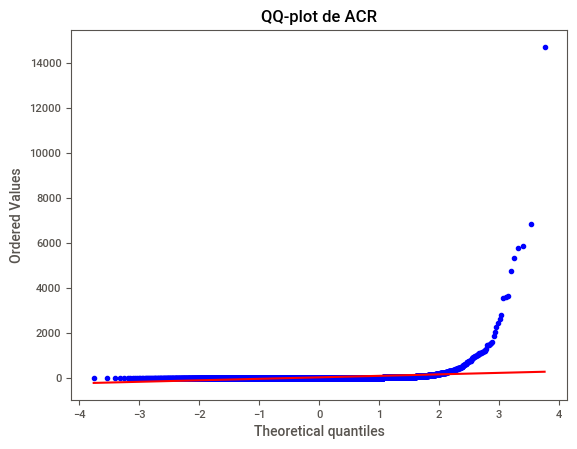

Test de Wilcoxon:
WilcoxonResult(statistic=np.float64(4790841.0), pvalue=np.float64(1.0))


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

# Seleccionar la columna y eliminar valores faltantes
acr = dataframe["albumin_creatinine_ratio"].dropna()

# Test de normalidad
print("Shapiro-Wilk:", stats.shapiro(acr))

# QQ-plot para observar la normalidad
stats.probplot(acr, dist="norm", plot=plt)
plt.title("QQ-plot de ACR")
plt.show()

# Contrastar la media con 30 mg/g
if stats.shapiro(acr).pvalue > 0.05:
    # Si no se rechaza la normalidad, usar test t de una muestra
    resultado = stats.ttest_1samp(acr, popmean=30, alternative="greater")
    print("Test t de una muestra:")
else:
    # Si hay evidencia de no normalidad, usar Wilcoxon
    resultado = stats.wilcoxon(acr - 30, alternative="greater")
    print("Test de Wilcoxon:")

print(resultado)

Hipotesis 2

/tmp/ipykernel_840/3768098669.py:11: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  print("Shapiro sin diabetes:", stats.shapiro(sin_diabetes))


Shapiro con diabetes: ShapiroResult(statistic=np.float64(0.9497889733713151), pvalue=np.float64(2.049006519771554e-16))
Shapiro sin diabetes: ShapiroResult(statistic=np.float64(nan), pvalue=np.float64(nan))


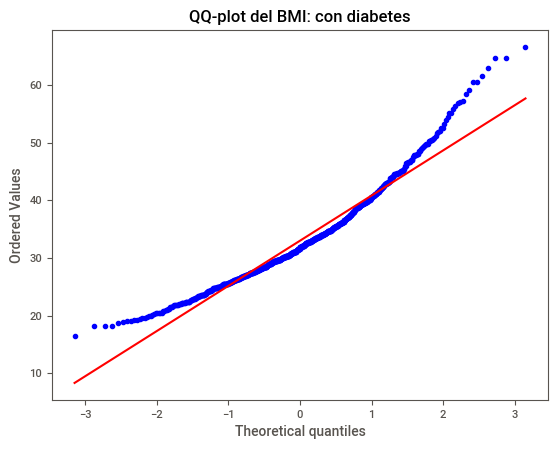

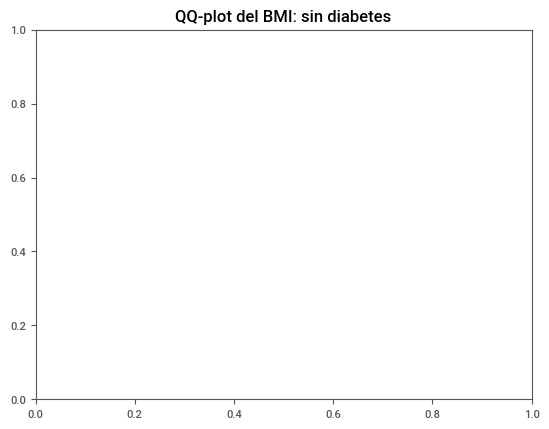

Test de Levene: LeveneResult(statistic=np.float64(nan), pvalue=np.float64(nan))
Test de Mann-Whitney U
MannwhitneyuResult(statistic=np.float64(nan), pvalue=np.float64(nan))


/tmp/ipykernel_840/3768098669.py:25: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  levene = stats.levene(con_diabetes, sin_diabetes)
/tmp/ipykernel_840/3768098669.py:45: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  resultado = stats.mannwhitneyu(


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

# Separar los grupos: 1 = diabetes, 0 = sin diabetes
con_diabetes = dataframe.loc[dataframe["diabetes_diagnosed"] == 1, "bmi"].dropna()
sin_diabetes = dataframe.loc[dataframe["diabetes_diagnosed"] == 0, "bmi"].dropna()

# Shapiro-Wilk para ambos grupos
print("Shapiro con diabetes:", stats.shapiro(con_diabetes))
print("Shapiro sin diabetes:", stats.shapiro(sin_diabetes))

# QQ-plots
plt.figure()
stats.probplot(con_diabetes, dist="norm", plot=plt)
plt.title("QQ-plot del BMI: con diabetes")
plt.show()

plt.figure()
stats.probplot(sin_diabetes, dist="norm", plot=plt)
plt.title("QQ-plot del BMI: sin diabetes")
plt.show()

# Levene para comparar las varianzas
levene = stats.levene(con_diabetes, sin_diabetes)
print("Test de Levene:", levene)

# Seleccionar el test según los supuestos
normal = (
    stats.shapiro(con_diabetes).pvalue > 0.05
    and stats.shapiro(sin_diabetes).pvalue > 0.05
)

if normal:
    # Student si las varianzas pueden considerarse iguales; Welch si no
    resultado = stats.ttest_ind(
        con_diabetes,
        sin_diabetes,
        equal_var=(levene.pvalue > 0.05),
        alternative="greater"
    )
    print("Test t de Student" if levene.pvalue > 0.05 else "Test t de Welch")
else:
    # Alternativa no paramétrica para comparar los grupos
    resultado = stats.mannwhitneyu(
        con_diabetes, sin_diabetes, alternative="greater"
    )
    print("Test de Mann-Whitney U")

print(resultado)

Hipotesis 3

                            OLS Regression Results                            
Dep. Variable:                   egfr   R-squared:                       0.440
Model:                            OLS   Adj. R-squared:                  0.439
Method:                 Least Squares   F-statistic:                     823.6
Date:                Thu, 22 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:16:36   Log-Likelihood:                -27320.
No. Observations:                6304   AIC:                         5.465e+04
Df Residuals:                    6297   BIC:                         5.470e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                 106.7664    

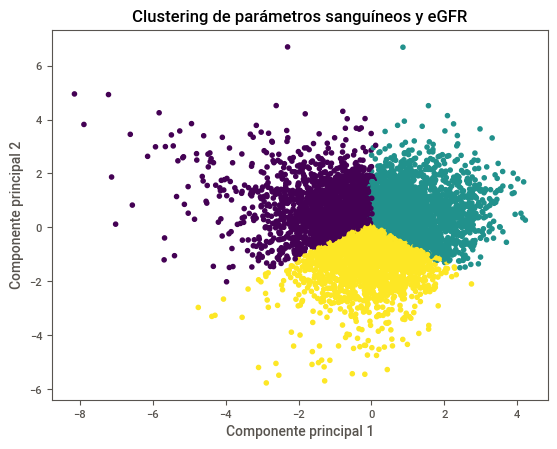

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Seleccionar las variables del modelo y eliminar filas incompletas
columnas = [
    "egfr", "blood_urea_nitrogen", "uric_acid",
    "albumin_serum", "phosphorus", "bicarbonate", "calcium"
]
datos = dataframe[columnas].dropna()

# Regresión lineal múltiple
X = datos.drop(columns="egfr")
y = datos["egfr"]

X = sm.add_constant(X)
modelo = sm.OLS(y, X).fit()

# Mostrar el resultado de la regresión
print(modelo.summary())

# Clustering: agrupar participantes según sus parámetros sanguíneos y eGFR
escalador = StandardScaler()
datos_norm = escalador.fit_transform(datos)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
grupos = kmeans.fit_predict(datos_norm)

# Reducir las dimensiones a dos componentes para graficar
pca = PCA(n_components=2)
datos_pca = pca.fit_transform(datos_norm)

plt.scatter(datos_pca[:, 0], datos_pca[:, 1], c=grupos)
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.title("Clustering de parámetros sanguíneos y eGFR")
plt.show()

Hipotesis 4

In [ ]:
import scipy.stats as stats
from statsmodels.stats.proportion import proportions_ztest

# Seleccionar participantes con CKD
casos = dataframe[dataframe["ckd_present"] == 1]

# Contar los casos blancos no hispanos
# Ajustar el texto si la categoría tiene otro nombre en el DataFrame
exito = (casos["ethnicity"] == "Non-Hispanic White").sum()
total = casos["ethnicity"].notna().sum()

# Test unilateral de una proporción: H0 p <= 0.5; H1 p > 0.5
resultado = proportions_ztest(
    count=exito,
    nobs=total,
    value=0.5,
    alternative="larger"
)

print("Casos blancos no hispanos:", exito)
print("Total de casos con etnia conocida:", total)
print("Proporción observada:", exito / total)
print("Test de una proporción:", resultado)

Casos blancos no hispanos: 4355
Total de casos con etnia conocida: 8341
Proporción observada: 0.5221196499220717
Test de una proporción: (np.float64(4.044293861520524), np.float64(2.6240530165323643e-05))


Hipotesis 5

Shapiro con CKD: ShapiroResult(statistic=np.float64(0.9614245979600332), pvalue=np.float64(1.5323728110589428e-31))
Shapiro sin CKD: ShapiroResult(statistic=np.float64(0.9723028518878728), pvalue=np.float64(2.1089481530983506e-25))


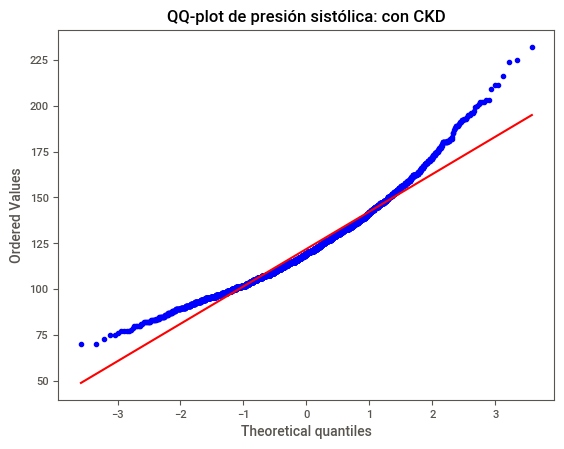

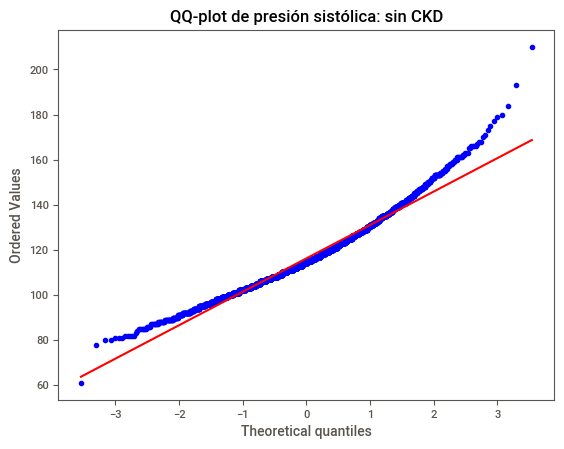

Test de Levene: LeveneResult(statistic=np.float64(263.89575409865256), pvalue=np.float64(2.3770155524785433e-58))
Test de Mann-Whitney U
MannwhitneyuResult(statistic=np.float64(8064903.0), pvalue=np.float64(4.717310892931647e-29))


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

# Separar participantes con CKD y sin CKD
con_ckd = dataframe.loc[dataframe["ckd_present"] == 1, "bp_systolic"].dropna()
sin_ckd = dataframe.loc[dataframe["ckd_present"] == 0, "bp_systolic"].dropna()

# Shapiro-Wilk para ambos grupos
print("Shapiro con CKD:", stats.shapiro(con_ckd))
print("Shapiro sin CKD:", stats.shapiro(sin_ckd))

# QQ-plots
plt.figure()
stats.probplot(con_ckd, dist="norm", plot=plt)
plt.title("QQ-plot de presión sistólica: con CKD")
plt.show()

plt.figure()
stats.probplot(sin_ckd, dist="norm", plot=plt)
plt.title("QQ-plot de presión sistólica: sin CKD")
plt.show()

# Levene para evaluar la igualdad de varianzas
levene = stats.levene(con_ckd, sin_ckd)
print("Test de Levene:", levene)

# Seleccionar el test
normal = (
    stats.shapiro(con_ckd).pvalue > 0.05
    and stats.shapiro(sin_ckd).pvalue > 0.05
)

if normal:
    resultado = stats.ttest_ind(
        con_ckd,
        sin_ckd,
        equal_var=(levene.pvalue > 0.05),
        alternative="greater"
    )
    print("Test t de Student" if levene.pvalue > 0.05 else "Test t de Welch")
else:
    resultado = stats.mannwhitneyu(
        con_ckd, sin_ckd, alternative="greater"
    )
    print("Test de Mann-Whitney U")

print(resultado)

Hipotesis 6

Optimization terminated successfully.
         Current function value: 0.579980
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:            ckd_present   No. Observations:                 5276
Model:                          Logit   Df Residuals:                     5268
Method:                           MLE   Df Model:                            7
Date:                Thu, 22 Oct 2026   Pseudo R-squ.:                  0.1622
Time:                        19:16:37   Log-Likelihood:                -3060.0
converged:                       True   LL-Null:                       -3652.2
Covariance Type:            nonrobust   LLR p-value:                1.623e-251
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   -3.5003      0.329    -10.624      0.000      -4.146      -2.855

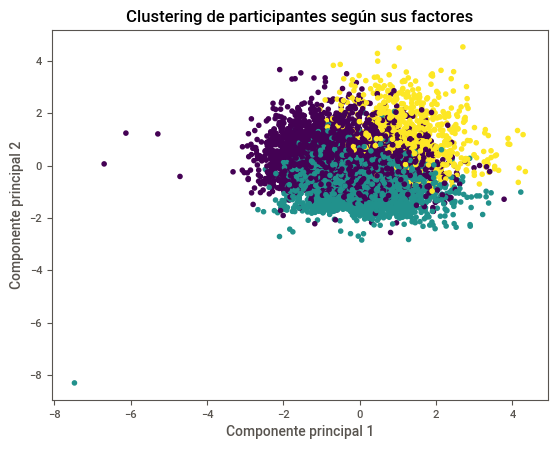

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Seleccionar las variables
columnas = [
    "ckd_present", "age", "gender", "bmi",
    "bp_systolic", "diabetes_diagnosed",
    "ever_smoked", "poverty_income_ratio"
]
datos = dataframe[columnas].dropna()

# Separar variable dependiente y variables explicativas
y = datos["ckd_present"]
X = datos.drop(columns="ckd_present")

# Convertir variables categóricas en columnas numéricas
X = pd.get_dummies(X, drop_first=True, dtype=int)

# Regresión logística múltiple
X = sm.add_constant(X)
modelo = sm.Logit(y, X).fit()

# Mostrar resultados
print(modelo.summary())

# Prueba global: ¿el conjunto de variables aporta información?
print("Estadístico de razón de verosimilitudes:", modelo.llr)
print("p-valor global:", modelo.llr_pvalue)

# Clustering exploratorio de los participantes según sus factores
escalador = StandardScaler()
datos_norm = escalador.fit_transform(X.drop(columns="const"))

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
grupos = kmeans.fit_predict(datos_norm)

# Reducir las dimensiones a dos componentes para graficar
pca = PCA(n_components=2)
datos_pca = pca.fit_transform(datos_norm)

plt.scatter(datos_pca[:, 0], datos_pca[:, 1], c=grupos)
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.title("Clustering de participantes según sus factores")
plt.show()